# Solving the n-Queens Problem using Local Search

Student Name: Đào Duy Hưng  
Student ID: 3122410158

I have used the following AI tools: ChatGPT (OpenAI) to assist with the Bài 5 modeling explanation, additional verification, and presentation. Review and understand all submitted work.

I understand that my submission needs to be my own work: [your initials – điền trước khi nộp]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# Tùy chọn cho Google Colab: không tự động thay đổi thư mục làm việc.
# Nếu cần lưu lên Drive, tự mount rồi chọn thư mục trong phiên chạy của bạn.
# from google.colab import drive
# drive.mount('/content/drive')
# (Không sử dụng os.chdir() với đường dẫn cá nhân.)


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


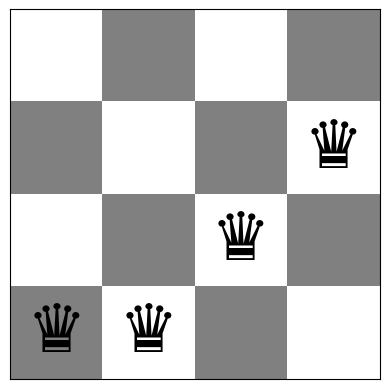

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


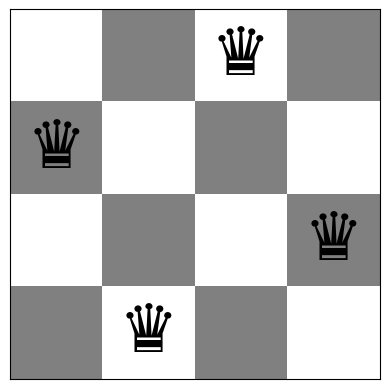

In [4]:
board = [1,3,0,2]
show_board(board)

# LAB04 – Bài 5. Biểu diễn bài toán n quân hậu (n-Queens)

### 5.1. Mục tiêu và mô hình hóa trạng thái

Bài thực hành sử dụng trực tiếp ba hàm gốc `random_board(n)`, `show_board(board)` và `conflicts(board)` trong notebook. Trong cách biểu diễn đang dùng, `board` là một vector $n$ phần tử:

$$board=[q_0,q_1,\dots,q_{n-1}],\qquad q_i\in\{0,1,\dots,n-1\}.$$

- Chỉ số `i` là **cột**; `board[i]` là **hàng** đặt quân hậu tại cột đó (chỉ số bắt đầu từ 0).
- Mỗi cột có đúng một quân hậu do mỗi cột ứng với đúng một phần tử của vector.
- Hai quân hậu tại cột $i$ và $j$ ($i<j$) xung đột khi $q_i=q_j$ (cùng hàng), hoặc $|q_i-q_j|=|i-j|$ (cùng đường chéo). Hai quân ở hai cột khác nhau nên không xảy ra xung đột cùng cột.
- Hàm mục tiêu là $h(board)=\mathrm{conflicts}(board)$, tức **số cặp quân hậu tấn công nhau**. Bài toán cần tối thiểu hóa $h$; nghiệm hợp lệ khi và chỉ khi $h(board)=0$.

Với $n$ cột và $n$ lựa chọn hàng cho mỗi cột, không gian biểu diễn có $n^n$ trạng thái. Chú ý đây là số cấu hình theo quy tắc một hậu/cột, **không** phải số nghiệm hợp lệ.

### 5.2. Cách hàm `conflicts()` tính số xung đột

Notebook sử dụng ba dãy đếm: số hậu theo **hàng** `q[i]`, theo đường chéo `i+q[i]`, và theo đường chéo `i-q[i]+n`. Mỗi nhóm chứa $k$ quân hậu sẽ đóng góp $\binom{k}{2}=k(k-1)/2$ cặp xung đột. Vì vậy:

$$h(board)=\sum_{r=0}^{n-1}\binom{R_r}{2}+\sum_{d}\binom{D_d^{(+)}}{2}+\sum_{d}\binom{D_d^{(-)}}{2}.$$

Phương pháp đếm theo nhóm này được đối chiếu bên dưới với hàm kiểm tra độc lập từng cặp quân hậu; hai cách phải luôn cho cùng kết quả.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Sử dụng cùng seed và thứ tự sinh để có thể chạy lại và nhận đúng kết quả.
BAI5_SEED = 20261020
np.random.seed(BAI5_SEED)
board_4 = random_board(4)
board_8 = random_board(8)
reference_4 = np.array([1, 3, 0, 2], dtype=int)
reference_8 = np.array([0, 4, 7, 5, 2, 6, 1, 3], dtype=int)

RESULT_DIR_B5 = Path('Lab04_Bai5_Results')
RESULT_DIR_B5.mkdir(exist_ok=True)

board_cases = [
    ('4-Queens ngẫu nhiên', np.asarray(board_4, dtype=int)),
    ('4-Queens mẫu [1,3,0,2]', reference_4),
    ('8-Queens ngẫu nhiên', np.asarray(board_8, dtype=int)),
    ('8-Queens đối chứng hợp lệ', reference_8),
]

rows = []
for name, b in board_cases:
    rows.append({
        'case': name, 'n': len(b), 'board': str(b.tolist()),
        'h_conflicts': int(conflicts(b)),
        'has_solution': bool(conflicts(b) == 0),
        'state_space_size': int(len(b) ** len(b)),
    })
boards_df = pd.DataFrame(rows)
boards_df.to_csv(RESULT_DIR_B5 / 'Bai5_Queens_Boards.csv', index=False, encoding='utf-8-sig')
print(f'Seed: {BAI5_SEED}. Bảng kết quả 4-Queens và 8-Queens:')
display(boards_df)


Seed: 20261020. Bảng kết quả 4-Queens và 8-Queens:


,case,n,board,h_conflicts,has_solution,state_space_size
0,4-Queens ngẫu nhiên,4,"[0, 0, 3, 0]",3,False,256
1,"4-Queens mẫu [1,3,0,2]",4,"[1, 3, 0, 2]",0,True,256
2,8-Queens ngẫu nhiên,8,"[6, 2, 3, 7, 4, 1, 6, 4]",5,False,16777216
3,8-Queens đối chứng hợp lệ,8,"[0, 4, 7, 5, 2, 6, 1, 3]",0,True,16777216


### 5.3. Kiểm chứng $h(board)=0$ và điều kiện không có cặp hậu xung đột

Viết một bộ kiểm tra tham chiếu khác cách cài đặt gốc: duyệt từng cặp cột $(i,j)$, $i<j$, và ghi nhận cặp xung đột theo hàng hoặc đường chéo. Với một bàn cờ có dữ liệu hợp lệ, số cặp trả về phải **bằng** `conflicts(board)`.

Ta kiểm tra toàn bộ $4^4=256$ vector của 4-Queens và thêm các bàn cờ 8-Queens sinh ngẫu nhiên với seed riêng. Kiểm tra đầy đủ 4-Queens là phép duyệt vét cạn để xác nhận tính đúng đắn trên mọi trạng thái của kích thước đó. Kiểm tra 8-Queens chỉ bao gồm tập mẫu, **không** phải chứng minh bằng thực nghiệm cho toàn bộ $8^8$ vector.

In [6]:
from itertools import product

def attack_pairs(board):
    """Liệt kê các cặp (i, j) cùng hàng hoặc cùng đường chéo, i < j."""
    b = np.asarray(board, dtype=int)
    n = len(b)
    if n < 1 or np.any(b < 0) or np.any(b >= n):
        raise ValueError('board phải là vector hợp lệ: 0 <= board[i] < n')
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            if b[i] == b[j] or abs(int(b[i])-int(b[j])) == j-i:
                pairs.append((i, j))
    return pairs

# Toàn bộ trạng thái của n=4; ngoài ra thử 500 cấu hình độc lập ở n=8.
rng_validation = np.random.default_rng(BAI5_SEED + 1)
all_4 = [np.asarray(b, dtype=int) for b in product(range(4), repeat=4)]
sampled_8 = [rng_validation.integers(0, 8, size=8) for _ in range(500)]
check_cases = [('4-Queens toàn bộ', all_4), ('8-Queens lấy mẫu', sampled_8)]
validation_rows = []
for description, collection in check_cases:
    mismatch = sum(int(conflicts(b) != len(attack_pairs(b))) for b in collection)
    zero_mismatch = sum(int((conflicts(b)==0) != (len(attack_pairs(b))==0)) for b in collection)
    validation_rows.append({'test': description, 'tested_boards': len(collection),
                            'count_mismatches': mismatch, 'zero_equivalence_mismatches': zero_mismatch,
                            'status': 'PASS' if mismatch==0 and zero_mismatch==0 else 'FAIL'})
    assert mismatch == 0 and zero_mismatch == 0, f'Lỗi bộ kiểm tra: {description}'

for name, b in board_cases:
    assert conflicts(b) == len(attack_pairs(b)), name
assert conflicts(reference_4) == 0
assert conflicts(reference_8) == 0

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(RESULT_DIR_B5 / 'Bai5_Queens_Validation.csv', index=False, encoding='utf-8-sig')
display(validation_df)
print('Các cặp xung đột của từng bàn cờ minh họa:')
pair_rows=[]
for name,b in board_cases:
    pair_rows.append({'case':name, 'n':len(b), 'h_conflicts': int(conflicts(b)),
                      'attacking_column_pairs':str(attack_pairs(b))})
pairs_df = pd.DataFrame(pair_rows)
pairs_df.to_csv(RESULT_DIR_B5 / 'Bai5_Queens_Conflict_Pairs.csv', index=False, encoding='utf-8-sig')
display(pairs_df)


,test,tested_boards,count_mismatches,zero_equivalence_mismatches,status
0,4-Queens toàn bộ,256,0,0,PASS
1,8-Queens lấy mẫu,500,0,0,PASS


Các cặp xung đột của từng bàn cờ minh họa:


,case,n,h_conflicts,attacking_column_pairs
0,4-Queens ngẫu nhiên,4,3,"[(0, 1), (0, 3), (1, 3)]"
1,"4-Queens mẫu [1,3,0,2]",4,0,[]
2,8-Queens ngẫu nhiên,8,5,"[(0, 5), (0, 6), (1, 2), (4, 6), (4, 7)]"
3,8-Queens đối chứng hợp lệ,8,0,[]


### 5.4. Trực quan hóa các bàn cờ bằng `show_board()`

Dưới đây là các hình từ **hàm gốc của giảng viên**: hai cấu hình ngẫu nhiên tương ứng $n=4$ và $n=8$, cấu hình mẫu `[1,3,0,2]`, và một nghiệm 8-Queens dùng để đối chiếu. Các hình lưu riêng phía dưới được vẽ lại theo cùng tọa độ `board[i]` để có tệp PNG có thể nộp cùng notebook.

4-Queens ngẫu nhiên:
Board with 3 conflicts.


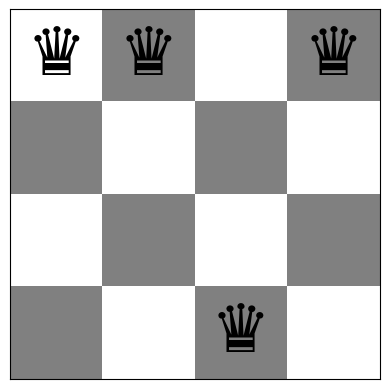

4-Queens mẫu [1, 3, 0, 2]:
Board with 0 conflicts.


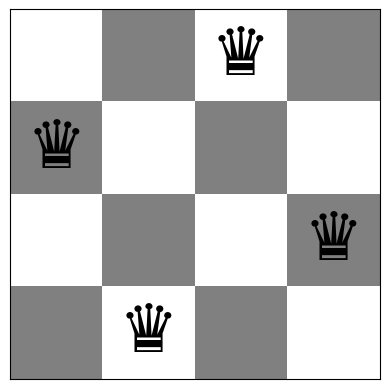

8-Queens ngẫu nhiên:
Board with 5 conflicts.


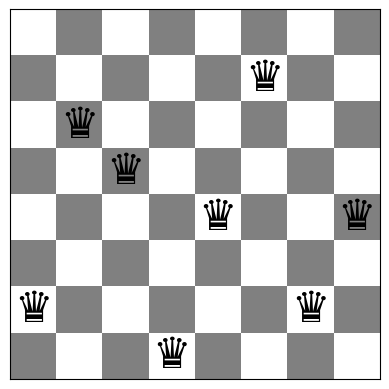

8-Queens nghiệm tham chiếu:
Board with 0 conflicts.


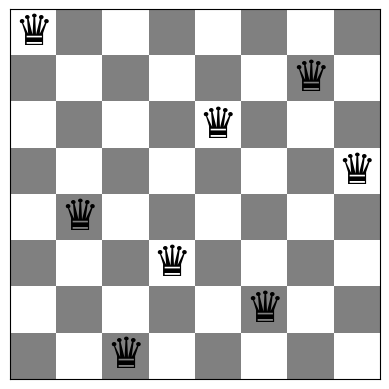

In [7]:
# Dùng trực tiếp show_board() như yêu cầu của Bài 5.
print('4-Queens ngẫu nhiên:')
show_board(board_4, fontsize=48)
print('4-Queens mẫu [1, 3, 0, 2]:')
show_board(reference_4, fontsize=48)
print('8-Queens ngẫu nhiên:')
show_board(board_8, fontsize=31)
print('8-Queens nghiệm tham chiếu:')
show_board(reference_8, fontsize=31)


In [8]:
# Xuất PNG từ dữ liệu đã kiểm chứng (không thay đổi hàm show_board() gốc).
from matplotlib.colors import ListedColormap

def draw_board_png(board, name, filename):
    b = np.asarray(board, dtype=int)
    n = len(b)
    squares = np.fromfunction(lambda r,c:(r+c)%2, (n,n))
    fig, ax = plt.subplots(figsize=(5.1,5.1))
    ax.imshow(squares, cmap=ListedColormap(['#f7f7f7','#909090']), vmin=0, vmax=1)
    for c, r in enumerate(b):
        ax.text(c, int(r), '♛', ha='center', va='center', color='black',
                fontsize=33 if n==4 else 23)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlabel('Cột (i)'); ax.set_ylabel('Hàng (board[i])')
    ax.set_title(f'{name} | h(board) = {int(conflicts(b))}', fontsize=11)
    ax.set_xticks(np.arange(-.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which='minor', color='black', linewidth=.55)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.set_xlim(-.5,n-.5); ax.set_ylim(n-.5,-.5)
    fig.tight_layout()
    fig.savefig(RESULT_DIR_B5 / filename, dpi=160)
    plt.close(fig)

for name,b in board_cases:
    n=len(b)
    filename = {
        '4-Queens ngẫu nhiên':'Bai5_4Queens_Random.png',
        '4-Queens mẫu [1,3,0,2]':'Bai5_4Queens_Reference.png',
        '8-Queens ngẫu nhiên':'Bai5_8Queens_Random.png',
        '8-Queens đối chứng hợp lệ':'Bai5_8Queens_Reference.png',
    }[name]
    draw_board_png(b, name, filename)
print('Đã xuất bốn hình PNG vào:', RESULT_DIR_B5)


Đã xuất bốn hình PNG vào: Lab04_Bai5_Results


### 5.5. Nhận xét kết quả và kết luận Bài 5

- Hai cấu hình được tạo bằng `random_board(n)` luôn có một quân hậu trên **mỗi cột**, nhưng vẫn có thể xung đột theo hàng và đường chéo. Điều này giải thích vì sao khởi tạo ngẫu nhiên chưa bảo đảm là nghiệm.
- Cấu hình mẫu `[1,3,0,2]` cho giá trị $h(board)=0$, vì không tồn tại cặp hậu cùng hàng hay cùng đường chéo. Cấu hình 8-Queens đối chứng cũng có $h=0$.
- Kết quả của `conflicts(board)` trùng với phép kiểm tra độc lập từng cặp hậu trên toàn bộ 256 trạng thái 4-Queens và 500 trạng thái 8-Queens được lấy mẫu. Nhận định “$h=0$ khi và chỉ khi không có cặp hậu tấn công nhau” còn được bảo đảm từ **định nghĩa hàm đếm số cặp xung đột**, không chỉ dựa vào các mẫu thử.
- Với biểu diễn một hậu/cột, $n^n$ là số trạng thái khả dĩ, trong khi một trạng thái đạt nghiệm phải thỏa tất cả các điều kiện hàng và đường chéo. Giá trị $h$ cung cấp thước đo để các thuật toán tìm kiếm cục bộ ở Task 1–6 cải thiện bàn cờ theo từng bước.

**Phạm vi:** Bài 5 chỉ mô hình hóa, hiển thị và kiểm thử hàm mục tiêu; các Task 1–6 bên dưới vẫn được giữ nguyên để tiếp tục hoàn thiện trong Bài 6–8 của Lab 04.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

### Bài 6 — Chuẩn bị và quy ước đo lường (Task 1–3)

Kế thừa `random_board()`, `conflicts()`, `show_board()` và dữ liệu Bài 5, không thay đổi các hàm của giảng viên.

- **Trạng thái**: `board[c]` là hàng của quân hậu ở cột `c`. Một nước đi thay hàng của **đúng một quân hậu trong cùng cột**. Mỗi trạng thái có $M=n(n-1)$ lân cận ($n\ge2$).
- **Hàm mục tiêu**: $h(board)=\mathrm{conflicts}(board)$; nghiệm hợp lệ nếu $h=0$.
- **Chính sách chấp nhận chung**: chỉ chấp nhận khi $h_{new}<h_{current}$; không di chuyển ngang trên plateau. `steps` là **số bước cải thiện được chấp nhận**, không phải số lân cận đã sinh.
- **`evaluations`**: số lần gọi `conflicts()` **bên trong một lượt chạy thuật toán**, bao gồm lần đánh giá ban đầu. Các phép kiểm tra độc lập ngoài thuật toán không tính vào chỉ số này.
- **Kết thúc**: `SOLVED` nếu $h=0$; `LOCAL_MINIMUM` nếu đã quét **toàn bộ** lân cận mà không thấy cải thiện; `TRY_LIMIT` nếu First-choice hết số lần thử thất bại liên tiếp; `STEP_LIMIT` nếu hết bước cải thiện cho phép.
- `LOCAL_MINIMUM` có thể chứa **plateau** khi tồn tại các lân cận có $h$ bằng hiện tại. Không được nhầm `TRY_LIMIT` với bằng chứng đã đạt cực tiểu cục bộ.

Để việc so sánh công bằng, cả ba biến thể dùng cùng toán tử chuyển hàng; dữ liệu đầu vào không bị sửa và có seed riêng cho các thuật toán ngẫu nhiên. Kết quả trả về thống nhất để phục vụ Bài 8 sau này.

In [9]:
# Bài 6: các hàm hỗ trợ dùng chung cho Task 1–3.
from time import perf_counter
from math import ceil, log
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RESULT_DIR_B6 = Path('Lab04_Bai6_Results')
RESULT_DIR_B6.mkdir(parents=True, exist_ok=True)


def _valid_board_b6(board):
    """Sao chép và kiểm tra vector một hậu/cột; không sửa board đầu vào."""
    b = np.asarray(board, dtype=np.int64).copy()
    if b.ndim != 1 or len(b) < 2 or np.any((b < 0) | (b >= len(b))):
        raise ValueError('board phải là vector n >= 2 và 0 <= board[i] < n')
    return b


def iter_local_neighbors(board):
    """Sinh M=n(n-1) lân cận; duyệt (cột, hàng mới) theo thứ tự cố định."""
    n = len(board)
    for col in range(n):
        for new_row in range(n):
            if new_row == int(board[col]):
                continue
            candidate = np.asarray(board, dtype=np.int64).copy()
            candidate[col] = new_row
            yield col, new_row, candidate


def random_local_neighbor(board, rng):
    """Lấy đều một nước đi chuyển hàng trong M lân cận, có hoàn lại."""
    n = len(board)
    col = int(rng.integers(n))
    old_row = int(board[col])
    offset = int(rng.integers(1, n))
    new_row = (old_row + offset) % n
    neighbor = board.copy()
    neighbor[col] = new_row
    return col, new_row, neighbor


def _finish_b6(name, board, h, steps, evaluations, history, status, elapsed_ms, tried=0):
    return {
        'algorithm': name, 'board': board.copy(), 'final_h': int(h),
        'steps': int(steps), 'evaluations': int(evaluations),
        'trials': int(tried), 'history': list(history),
        'status': status, 'solved': bool(h == 0),
        'elapsed_ms': float(elapsed_ms),
    }


In [10]:
def steepest_ascent(board, max_steps=1000):
    """Task 1. Chọn lân cận có h nhỏ nhất sau khi đánh giá toàn bộ M nước đi."""
    current = _valid_board_b6(board)
    started = perf_counter()
    current_h = int(conflicts(current))
    evaluations, steps = 1, 0
    history, status = [current_h], None
    while current_h > 0 and steps < max_steps:
        best_board, best_h = None, current_h
        # KHÔNG dừng ngay khi gặp ứng viên tốt: kiểm tra hết các lân cận.
        for _, _, candidate in iter_local_neighbors(current):
            candidate_h = int(conflicts(candidate))
            evaluations += 1
            if candidate_h < best_h:
                best_h, best_board = candidate_h, candidate
        if best_board is None:
            status = 'LOCAL_MINIMUM'
            break
        current, current_h = best_board, best_h
        steps += 1
        history.append(current_h)
    if status is None:
        status = 'SOLVED' if current_h == 0 else 'STEP_LIMIT'
    return _finish_b6('Steepest-ascent', current, current_h, steps, evaluations,
                      history, status, (perf_counter()-started)*1000)

# Kiểm tra bắt buộc trên nghiệm đã biết.
assert steepest_ascent(np.array([1, 3, 0, 2]))['status'] == 'SOLVED'
print('Task 1: Steepest-ascent đã được định nghĩa và kiểm tra.')


Task 1: Steepest-ascent đã được định nghĩa và kiểm tra.


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

### Task 2 – Cài đặt Inefficient Stochastic

Duyệt đủ mọi nước đi trong từng vòng và đưa các nước đi có $h_{new}<h_{current}$ vào danh sách `improving`. Chọn ngẫu nhiên một phần tử trong danh sách; khi danh sách rỗng, dừng tại `LOCAL_MINIMUM`.

In [11]:
def inefficient_stochastic(board, seed=0, max_steps=1000):
    """Task 2. Đánh giá toàn bộ lân cận, chọn đều ngẫu nhiên trong tập cải thiện."""
    current = _valid_board_b6(board)
    rng = np.random.default_rng(seed)
    started = perf_counter()
    current_h = int(conflicts(current))
    evaluations, steps = 1, 0
    history, status = [current_h], None
    while current_h > 0 and steps < max_steps:
        improving = []
        for _, _, candidate in iter_local_neighbors(current):
            candidate_h = int(conflicts(candidate))
            evaluations += 1
            if candidate_h < current_h:
                improving.append((candidate_h, candidate))
        if not improving:
            status = 'LOCAL_MINIMUM'
            break
        selected_h, selected_board = improving[int(rng.integers(len(improving)))]
        current, current_h = selected_board, selected_h
        steps += 1
        history.append(current_h)
    if status is None:
        status = 'SOLVED' if current_h == 0 else 'STEP_LIMIT'
    return _finish_b6('Stochastic (all)', current, current_h, steps, evaluations,
                      history, status, (perf_counter()-started)*1000)

assert inefficient_stochastic([1, 3, 0, 2], seed=1)['final_h'] == 0
print('Task 2: Inefficient Stochastic đã được định nghĩa và kiểm tra.')


Task 2: Inefficient Stochastic đã được định nghĩa và kiểm tra.


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

### Task 3 – Cài đặt First-choice / Efficient Stochastic

Ở mỗi lần thử chỉ sinh **một** nước đi ngẫu nhiên hợp lệ; nhận ngay nếu cải thiện. Khi không tìm được cải thiện sau số lần thử liên tiếp đã quy định, dừng `TRY_LIMIT` (không xem là chứng nhận cực tiểu).

In [12]:
def efficient_stochastic(board, seed=0, max_steps=1000,
                         max_no_improvement=None, max_evaluations=None):
    """Task 3 (First-choice): thử lần lượt 1 lân cận ngẫu nhiên; nhận bước đầu cải thiện."""
    current = _valid_board_b6(board)
    rng = np.random.default_rng(seed)
    n = len(current)
    M = n * (n - 1)
    # P(bỏ sót một nước đi CỐ ĐỊNH sau x lần thử đều, có hoàn lại)
    # = (1 - 1/M)^x <= 0.05 khi x >= ceil(log(0.05)/log(1-1/M)).
    if max_no_improvement is None:
        max_no_improvement = ceil(log(0.05) / log(1 - 1/M))
    if max_no_improvement < 1:
        raise ValueError('max_no_improvement phải >= 1')
    if max_evaluations is None:
        max_evaluations = 1 + (max_steps + 1) * max_no_improvement
    started = perf_counter()
    current_h = int(conflicts(current))
    evaluations, steps, attempted = 1, 0, 0
    failures = 0
    history, status = [current_h], None
    while current_h > 0 and steps < max_steps:
        if evaluations >= max_evaluations:
            status = 'EVAL_LIMIT'
            break
        _, _, candidate = random_local_neighbor(current, rng)
        candidate_h = int(conflicts(candidate))
        evaluations += 1
        attempted += 1
        if candidate_h < current_h:
            current, current_h = candidate, candidate_h
            steps += 1
            failures = 0
            history.append(current_h)
        else:
            failures += 1
            if failures >= max_no_improvement:
                status = 'TRY_LIMIT'
                break
    if status is None:
        status = 'SOLVED' if current_h == 0 else 'STEP_LIMIT'
    result = _finish_b6('First-choice', current, current_h, steps, evaluations,
                        history, status, (perf_counter()-started)*1000, attempted)
    result['failure_limit'] = int(max_no_improvement)
    return result

assert efficient_stochastic([1, 3, 0, 2], seed=1)['status'] == 'SOLVED'
print('Task 3: Efficient Stochastic/First-choice đã được định nghĩa và kiểm tra.')


Task 3: Efficient Stochastic/First-choice đã được định nghĩa và kiểm tra.


### Bài 6 — Thực nghiệm Task 1–3 trên $n=4$ và $n=8$

Dữ liệu demo dùng lại `board_4`, `board_8` của Bài 5 (`BAI5_SEED=20261020`). Mỗi lần chạy ghi `final_h`, `steps`, `evaluations`, `elapsed_ms`, `status` và `history`.

Phần thống kê bổ sung sử dụng **30 bàn cờ khởi tạo độc lập cho mỗi $n$** và cùng một bàn cờ cho cả ba thuật toán trong mỗi lượt. Tỷ lệ thành công tính theo điều kiện $h=0$. Đây là khảo sát dành cho **Bài 6**; yêu cầu tối thiểu **100 lượt** trong Task 6 được giữ để hoàn thành ở **Bài 8**, không được xem là đã thực hiện tại đây.

**Lưu ý về ngân sách:** Steepest và Stochastic (all) phải quét đủ $M$ ứng viên mỗi vòng (kể cả vòng cuối khi phát hiện không còn cải thiện). First-choice sinh một ứng viên mỗi lần thử, có hoàn lại; sau $x=\lceil\log(0.05)/\log(1-1/M)\rceil$ lần thử liên tiếp không thành công sẽ dừng `TRY_LIMIT`. Mức 5% chỉ là chặn xác suất **bỏ sót một nước đi cải thiện cố định**, không phải bảo đảm xác suất bỏ sót bất kỳ bước cải thiện nào bằng 0.

In [13]:
# Một lượt chung cho cả ba thuật toán trên cùng board_4 và board_8.
ALGOS_B6 = [
    ('Steepest-ascent', lambda b, seed: steepest_ascent(b)),
    ('Stochastic (all)', lambda b, seed: inefficient_stochastic(b, seed=seed)),
    ('First-choice', lambda b, seed: efficient_stochastic(b, seed=seed)),
]

def summary_record_b6(n, kind, label, trial, start_h, result):
    return {
        'n': n, 'dataset': kind, 'trial': trial, 'algorithm': label,
        'initial_h': int(start_h), 'final_h': result['final_h'],
        'steps': result['steps'], 'evaluations': result['evaluations'],
        'elapsed_ms': result['elapsed_ms'], 'status': result['status'],
        'solved': result['solved'],
    }

demo_rows, demo_results = [], {}
for n, initial in [(4, board_4), (8, board_8)]:
    for ai, (label, fn) in enumerate(ALGOS_B6):
        result = fn(initial, seed=BAI5_SEED + ai)
        assert result['final_h'] == conflicts(result['board'])
        assert np.array_equal(np.asarray(initial), board_4 if n == 4 else board_8)
        demo_rows.append(summary_record_b6(n, 'demo', label, 0, conflicts(initial), result))
        demo_results[(n,label)] = result

demo_b6 = pd.DataFrame(demo_rows)
demo_b6.to_csv(RESULT_DIR_B6/'Bai6_HillClimbing_Demo.csv', index=False, encoding='utf-8-sig')
print('Bài 6: minh họa một lượt với cùng trạng thái đầu')
display(demo_b6[['n','algorithm','initial_h','final_h','steps','evaluations','elapsed_ms','status']].round(4))

# 30 lượt / kích thước / thuật toán = 180 lượt chạy trong bảng khảo sát Bài 6.
TRIALS_B6 = 30
trial_rng_b6 = np.random.default_rng(BAI5_SEED + 6)
trial_rows_b6 = []
for n in [4, 8]:
    for trial in range(TRIALS_B6):
        initial = trial_rng_b6.integers(0, n, size=n, dtype=np.int64)
        initial_h = int(conflicts(initial))
        for ai, (label, fn) in enumerate(ALGOS_B6):
            seed = BAI5_SEED + 1000*n + 10*trial + ai
            result = fn(initial, seed=seed)
            assert result['final_h'] == conflicts(result['board'])
            trial_rows_b6.append(summary_record_b6(n, 'random', label, trial, initial_h, result))

trials_b6 = pd.DataFrame(trial_rows_b6)
trials_b6.to_csv(RESULT_DIR_B6/'Bai6_HillClimbing_Trials.csv', index=False, encoding='utf-8-sig')
summary_b6 = (trials_b6.groupby(['n','algorithm'], as_index=False)
              .agg(runs=('trial','count'), success_rate=('solved','mean'),
                   mean_final_h=('final_h','mean'), mean_steps=('steps','mean'),
                   mean_evaluations=('evaluations','mean'), mean_ms=('elapsed_ms','mean')))
summary_b6['success_percent'] = summary_b6['success_rate'] * 100
summary_b6.to_csv(RESULT_DIR_B6/'Bai6_HillClimbing_Summary.csv', index=False, encoding='utf-8-sig')
print(f'Thống kê Bài 6: {TRIALS_B6} lượt/kích thước/thuật toán')
display(summary_b6[['n','algorithm','runs','success_percent','mean_final_h','mean_steps','mean_evaluations','mean_ms']].round(3))


Bài 6: minh họa một lượt với cùng trạng thái đầu


,n,algorithm,initial_h,final_h,steps,evaluations,elapsed_ms,status
0,4,Steepest-ascent,3,0,2,25,0.1281,SOLVED
1,4,Stochastic (all),3,0,2,25,0.1433,SOLVED
2,4,First-choice,3,2,1,38,0.2564,TRY_LIMIT
3,8,Steepest-ascent,5,1,3,225,1.4181,LOCAL_MINIMUM
4,8,Stochastic (all),5,1,4,281,2.7561,LOCAL_MINIMUM
5,8,First-choice,5,1,4,325,3.9995,TRY_LIMIT


Thống kê Bài 6: 30 lượt/kích thước/thuật toán


,n,algorithm,runs,success_percent,mean_final_h,mean_steps,mean_evaluations,mean_ms
0,4,First-choice,30,46.667,0.667,2.033,29.233,0.245
1,4,Steepest-ascent,30,40.000,0.700,1.500,26.200,0.137
2,4,Stochastic (all),30,36.667,0.733,1.967,32.200,0.179
3,8,First-choice,30,16.667,1.167,4.967,206.767,2.446
4,8,Steepest-ascent,30,16.667,1.300,3.167,225.000,1.844
5,8,Stochastic (all),30,16.667,1.267,5.233,340.733,2.847


### Bài 6 — Kiểm thử tính đúng đắn và nguyên nhân dừng

Các `assert` bên dưới kiểm tra không thay đổi đầu vào, lân cận hợp lệ, tính đơn điệu nghiêm ngặt của lịch sử $h$, tính đúng của bộ đếm `evaluations`, và các điều kiện dừng. Trạng thái `LOCAL_MINIMUM` được xác minh bằng cách duyệt toàn bộ lân cận; `TRY_LIMIT` chỉ kiểm soát ngân sách mẫu ngẫu nhiên. Để nhận biết plateau tại điểm dừng, ta đếm số lân cận có $h$ bằng giá trị hiện tại mà không khẳng định đây là nguyên nhân duy nhất khiến thuật toán thất bại.

In [14]:
# Kiểm thử tích hợp: không sửa dữ liệu, đếm evaluation chính xác, đúng chuẩn trạng thái.
def analyze_stop_b6(board):
    b = _valid_board_b6(board)
    current_h = int(conflicts(b))
    values = [int(conflicts(nb)) for _, _, nb in iter_local_neighbors(b)]
    return {
        'h': current_h, 'n_improving': sum(x < current_h for x in values),
        'n_equal': sum(x == current_h for x in values),
        'n_worse': sum(x > current_h for x in values),
    }

check_rows_b6 = []
for n in (4, 8):
    initial = (board_4 if n == 4 else board_8).copy()
    for ai, (label, fn) in enumerate(ALGOS_B6):
        r = fn(initial, seed=555+ai)
        assert np.array_equal(initial, board_4 if n == 4 else board_8)
        assert r['steps'] == len(r['history']) - 1
        assert r['history'][0] == int(conflicts(initial))
        assert all(a > b for a,b in zip(r['history'], r['history'][1:]))
        assert r['final_h'] == int(conflicts(r['board']))
        assert len(list(iter_local_neighbors(r['board']))) == n*(n-1)
        assert r['evaluations'] >= r['steps'] + 1
        if label != 'First-choice':
            assert (r['evaluations'] - 1) % (n*(n-1)) == 0
        if r['status'] == 'LOCAL_MINIMUM':
            assert analyze_stop_b6(r['board'])['n_improving'] == 0
        if r['status'] == 'SOLVED':
            assert r['final_h'] == 0
        status_detail = analyze_stop_b6(r['board'])
        check_rows_b6.append({
            'n':n, 'algorithm':label, 'status':r['status'],
            'final_h':r['final_h'], 'equal_neighbors_at_stop':status_detail['n_equal'],
            'improving_neighbors_at_stop':status_detail['n_improving'],
            'test_status':'PASS'
        })

# Nghiệm mẫu phải dừng ngay sau 1 lần đánh giá, không tự ý di chuyển.
for _, fn in ALGOS_B6:
    for solution in (reference_4, reference_8):
        r = fn(solution, seed=11)
        assert r['status'] == 'SOLVED' and r['steps'] == 0 and r['evaluations'] == 1

# Với First-choice, budget có thể dẫn đến TRY_LIMIT chứ không kết luận cực tiểu.
forced = efficient_stochastic([0, 0, 0, 0], seed=1, max_no_improvement=1)
assert forced['status'] in ('TRY_LIMIT','SOLVED','STEP_LIMIT')

validation_b6 = pd.DataFrame(check_rows_b6)
validation_b6.to_csv(RESULT_DIR_B6/'Bai6_HillClimbing_Validation.csv', index=False, encoding='utf-8-sig')
print('Kiểm thử 3 thuật toán trên hai kích thước: đạt.')
display(validation_b6)


Kiểm thử 3 thuật toán trên hai kích thước: đạt.


,n,algorithm,status,final_h,equal_neighbors_at_stop,improving_neighbors_at_stop,test_status
0,4,Steepest-ascent,SOLVED,0,0,0,PASS
1,4,Stochastic (all),LOCAL_MINIMUM,1,1,0,PASS
2,4,First-choice,TRY_LIMIT,1,1,0,PASS
3,8,Steepest-ascent,LOCAL_MINIMUM,1,1,0,PASS
4,8,Stochastic (all),LOCAL_MINIMUM,1,4,0,PASS
5,8,First-choice,TRY_LIMIT,2,8,0,PASS


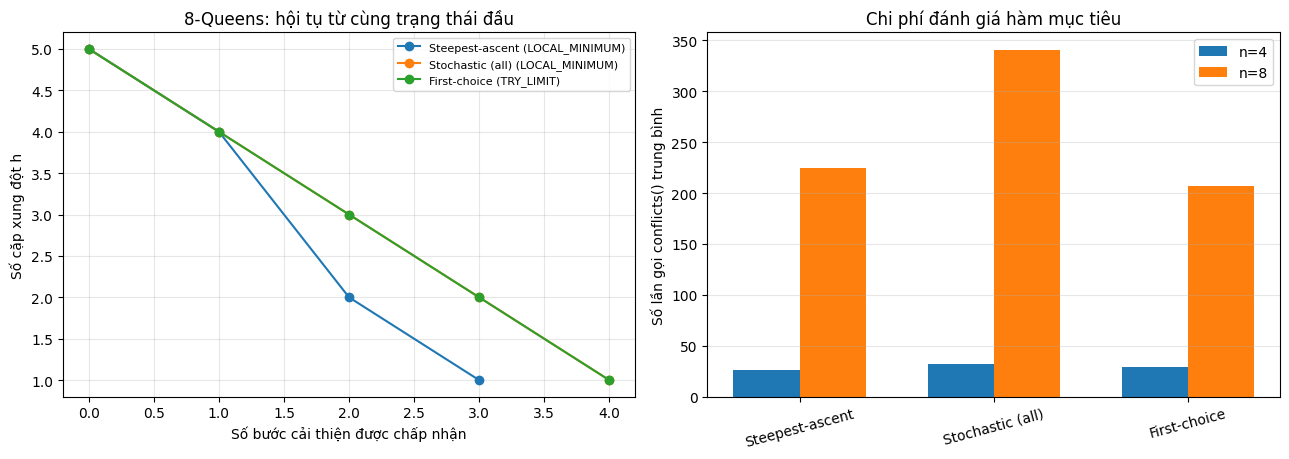

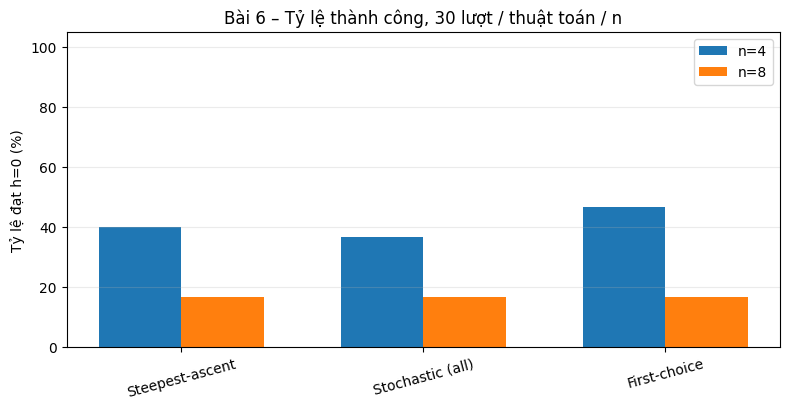

In [15]:
# Biểu đồ 1: quá trình giảm số cặp hậu xung đột trên CÙNG bàn cờ n=8.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for label,_ in ALGOS_B6:
    r = demo_results[(8,label)]
    axes[0].plot(range(len(r['history'])), r['history'], marker='o', label=f"{label} ({r['status']})")
axes[0].set(title='8-Queens: hội tụ từ cùng trạng thái đầu',
            xlabel='Số bước cải thiện được chấp nhận', ylabel='Số cặp xung đột h')
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

# Biểu đồ 2: chi phí đánh giá trung bình từ 30 lượt độc lập.
labels = [label for label,_ in ALGOS_B6]
x = np.arange(len(labels))
width = .34
for k,n in enumerate([4,8]):
    vals = [summary_b6[(summary_b6.n==n)&(summary_b6.algorithm==label)].iloc[0].mean_evaluations
            for label in labels]
    axes[1].bar(x + (k-.5)*width, vals, width, label=f'n={n}')
axes[1].set(xticks=x, xticklabels=labels, ylabel='Số lần gọi conflicts() trung bình',
            title='Chi phí đánh giá hàm mục tiêu')
axes[1].tick_params(axis='x', labelrotation=15)
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULT_DIR_B6/'Bai6_HillClimbing_Convergence_Evaluations.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8.0,4.2))
for k,n in enumerate([4,8]):
    vals = [summary_b6[(summary_b6.n==n)&(summary_b6.algorithm==label)].iloc[0].success_percent
            for label in labels]
    ax.bar(x + (k-.5)*width, vals, width, label=f'n={n}')
ax.set(xticks=x, xticklabels=labels, ylabel='Tỷ lệ đạt h=0 (%)',
       title=f'Bài 6 – Tỷ lệ thành công, {TRIALS_B6} lượt / thuật toán / n', ylim=(0,105))
ax.tick_params(axis='x', labelrotation=15)
ax.legend()
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
fig.savefig(RESULT_DIR_B6/'Bai6_HillClimbing_Success_Rates.png', dpi=160)
plt.show()


### Bài 6 — Nhận xét và kết luận

1. **Steepest-ascent** tìm trạng thái tốt nhất trong toàn bộ $M=n(n-1)$ lân cận trước khi di chuyển. Có thể có ít **bước chấp nhận** nhưng nhiều **lần đánh giá**, kể cả vòng quét cuối xác định cực tiểu cục bộ.
2. **Inefficient Stochastic** cũng đánh giá toàn bộ $M$ lân cận, nhưng chọn ngẫu nhiên trong tập cải thiện. Nhờ vậy, đường đi có thể khác nhau tùy seed; không đảm bảo số bước thấp nhất.
3. **Efficient Stochastic/First-choice** thử lần lượt một nước đi ngẫu nhiên và chấp nhận ngay nếu giảm $h$. Phương pháp tránh phải lập toàn bộ tập lân cận, nhưng vì lấy mẫu có hoàn lại nên vẫn có thể thử lặp và bỏ sót một bước tốt. `TRY_LIMIT` không phải chứng minh cực tiểu cục bộ.
4. Ba thuật toán chỉ chấp nhận bước **giảm nghiêm ngặt**, không di chuyển trên plateau và có thể mắc kẹt khi $h>0$. Sự tồn tại của lân cận bằng giá trị tại điểm dừng được ghi trong CSV kiểm thử.
5. Các phép đo trên $n=4$ và $n=8$ là mẫu minh họa và **30 lần chạy/thuật toán/kích thước**, không đủ để kết luận một chiến lược luôn vượt trội. Việc thống kê ít nhất 100 lượt và Random Restart/Simulated Annealing thuộc **Bài 7–8**.

**Kết luận:** Task 1–3 đã được lập trình thành các hàm độc lập; toàn bộ nhiệm vụ Bài 5 được bảo lưu. Các cell `Code and description go here` ở Task 4–6 và Advanced task vẫn được giữ nguyên cho các bài tiếp theo.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

### Bài 7 – Task 4: Random Restart

Cả ba phương pháp kế thừa từ Bài 6: Steepest-ascent, Inefficient Stochastic và Efficient Stochastic (First-choice). Cơ chế khởi động lại không làm thay đổi phép sinh lân cận; mỗi lần vẫn chỉ đổi **một quân hậu sang hàng khác trong cùng cột**.

- **Quy ước ngân sách:** `max_restarts = 100` cho phép tối đa **100 lần tạo lại bàn cờ sau lượt ban đầu**, tức nhiều nhất 101 lượt Hill Climbing. Phân biệt `runs` với `restarts_used = runs - 1`.
- **Nghiệm được trả về:** `best_board` có số cặp xung đột **nhỏ nhất trong tất cả lượt chạy**. Nếu có một lượt đạt `h=0`, trạng thái `SOLVED` và kết thúc ngay; nếu hết ngân sách thì `RESTART_LIMIT` (không được kết luận vô nghiệm).
- **Số lần đánh giá:** cộng dồn mọi `evaluations` của các lượt Hill Climbing, gồm mỗi lần tính trạng thái khởi tạo. Tổng số bước `steps` tính toàn bộ nước đi cải thiện đã chấp nhận qua tất cả các lượt.
- **Random seed:** dùng một `numpy.random.Generator` cục bộ để sinh bàn cờ khởi động lại và seed cho các thuật toán ngẫu nhiên. Không thay đổi dữ liệu đầu vào của người gọi.

Task 4 không được nhầm với thuật toán Random Forest trong Machine Learning.

In [16]:
# Task 4 — Random Restart cho ba biến thể Hill Climbing của Bài 6.
# max_restarts=100 nghĩa là một lượt khởi tạo đầu + tối đa 100 lần khởi động lại.
from time import perf_counter
import numpy as np


def random_restart_hill_climbing(board, method='steepest', seed=20261020,
                                 max_restarts=100, max_steps=1000,
                                 first_choice_failure_limit=None):
    """Chạy lại HC bằng các board khác nhau; trả về nghiệm TỐT NHẤT từng thấy.

    method: 'steepest', 'stochastic', 'first_choice'.
    evaluations = tổng số lần conflicts() được gọi trong các lượt HC.
    elapsed_ms = thời gian thực thi toàn bộ phương pháp (bao gồm restart).
    """
    start_board = _valid_board_b6(board)
    if method not in ('steepest', 'stochastic', 'first_choice'):
        raise ValueError('method phải là steepest/stochastic/first_choice')
    if not isinstance(max_restarts, (int, np.integer)) or max_restarts < 0:
        raise ValueError('max_restarts phải là số nguyên không âm')
    rng = np.random.default_rng(seed)
    best_board, best_h = start_board.copy(), float('inf')
    evaluations = steps = 0
    restart_trace, best_history = [], []
    started = perf_counter()
    for run_index in range(max_restarts + 1):
        # Lượt đầu: đúng đầu vào. Các lượt còn lại: khởi tạo ngẫu nhiên độc lập.
        start = start_board.copy() if run_index == 0 else rng.integers(0, len(start_board), size=len(start_board))
        child_seed = int(rng.integers(0, 2**32 - 1))
        if method == 'steepest':
            result = steepest_ascent(start, max_steps=max_steps)
        elif method == 'stochastic':
            result = inefficient_stochastic(start, seed=child_seed, max_steps=max_steps)
        else:
            result = efficient_stochastic(start, seed=child_seed, max_steps=max_steps,
                                          max_no_improvement=first_choice_failure_limit)
        evaluations += result['evaluations']
        steps += result['steps']
        if result['final_h'] < best_h:
            best_h = int(result['final_h'])
            best_board = result['board'].copy()
        restart_trace.append({
            'run': int(run_index + 1), 'restarts_used': int(run_index),
            'initial_h': int(result['history'][0]), 'final_h': int(result['final_h']),
            'best_h_so_far': int(best_h), 'evaluations': int(result['evaluations']),
            'steps': int(result['steps']), 'status': result['status'],
        })
        best_history.append(int(best_h))
        if best_h == 0:
            break
    runs = len(restart_trace)
    return {
        'algorithm': 'RR-' + method, 'board': best_board.copy(), 'final_h': int(best_h),
        'solved': bool(best_h == 0), 'status': 'SOLVED' if best_h == 0 else 'RESTART_LIMIT',
        'runs': int(runs), 'restarts_used': int(runs - 1),
        'max_restarts': int(max_restarts), 'steps': int(steps),
        'evaluations': int(evaluations), 'elapsed_ms': (perf_counter() - started) * 1000,
        'history': best_history, 'restart_trace': restart_trace,
    }

# Kiểm thử nhanh cho Task 4.
rr_solved = random_restart_hill_climbing(reference_4, seed=3)
assert rr_solved['solved'] and rr_solved['runs'] == 1 and rr_solved['restarts_used'] == 0
assert rr_solved['evaluations'] == 1 and rr_solved['steps'] == 0
rr_bounded = random_restart_hill_climbing(board_8, seed=3, max_restarts=0)
assert rr_bounded['runs'] == 1 and rr_bounded['restarts_used'] == 0
assert rr_bounded['final_h'] == conflicts(rr_bounded['board'])
print('Task 4: Random Restart đã sẵn sàng, gồm 3 biến thể Hill Climbing.')

Task 4: Random Restart đã sẵn sàng, gồm 3 biến thể Hill Climbing.


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Bài 7 – Task 5: Simulated Annealing và hai lịch nhiệt

Tại mỗi vòng, tạo một lân cận ngẫu nhiên, đặt $\Delta h=h_{new}-h_{current}$. Bước $\Delta h\le0$ được chấp nhận; nếu $\Delta h>0$, chấp nhận với xác suất $p=\exp(-\Delta h/T)$. Nhiệt độ giảm theo một trong hai lịch:

- **Exponential:** $T(t)=T_0\alpha^t$, với $0<\alpha<1$.
- **Linear:** $T(t)=\max(0,T_0-\eta t)$, với $\eta>0$.

Trong phép thử sử dụng $T_0=3,\alpha=0.995,\eta=0.002$ và tối đa 2000 lượt thử lân cận. Hai lịch xuất phát cùng nhiệt độ $T(0)=3$. Khi Linear về 0, thuật toán vẫn có thể chấp nhận bước không xấu hơn ($\Delta h\le0$), nhưng không chấp nhận $\Delta h>0$. Cùng một giới hạn số lượt thử giúp so sánh minh bạch, dù phân bố các bước được chấp nhận khác nhau.

Lưu `current_h` và `best_h` riêng: số xung đột của trạng thái hiện tại có thể **tăng**, nhưng nghiệm tốt nhất từng gặp chỉ **giảm hoặc giữ nguyên**. `ITERATION_LIMIT` nghĩa là chưa tìm được $h=0$ trong ngân sách, **không phải** chứng minh bài toán vô nghiệm.

In [17]:
# Task 5 — Simulated Annealing với hai lịch giảm nhiệt và seed tái lập.
import math
from time import perf_counter
import numpy as np


def annealing_temperature(t, schedule='exponential', T0=3.0, alpha=0.995, eta=0.002):
    """t bắt đầu tại 0; hai lịch dùng cùng T(0)=T0."""
    if T0 <= 0:
        raise ValueError('T0 phải lớn hơn 0')
    if schedule == 'exponential':
        if not 0 < alpha < 1:
            raise ValueError('Lịch exponential yêu cầu 0 < alpha < 1')
        return float(T0 * alpha**t)
    if schedule == 'linear':
        if eta <= 0:
            raise ValueError('Lịch linear yêu cầu eta > 0')
        return float(max(0.0, T0 - eta*t))
    raise ValueError('schedule phải là exponential hoặc linear')


def simulated_annealing_queens(board, seed=20261020, schedule='exponential',
                               T0=3.0, alpha=0.995, eta=0.002,
                               max_iterations=2000):
    """Duy trì current và best riêng; SA có thể chấp nhận bước làm tăng h.

    Quy ước Δ = h(candidate) − h(current):
      Δ <= 0: chấp nhận; Δ > 0: chấp nhận với xác suất exp(-Δ/T).
    Khi lịch linear cho T=0: từ chối Δ>0, tiếp tục với ngân sách chung.
    evaluations gồm 1 lần tính h đầu và 1 lần mỗi lần thử lân cận.
    """
    current = _valid_board_b6(board)
    if not isinstance(max_iterations, (int, np.integer)) or max_iterations < 0:
        raise ValueError('max_iterations phải là số nguyên không âm')
    # Xác thực tham số kể cả trường hợp trạng thái bắt đầu đã là nghiệm.
    annealing_temperature(0, schedule, T0, alpha, eta)
    rng = np.random.default_rng(seed)
    started = perf_counter()
    current_h = int(conflicts(current))
    best_h, best_board = current_h, current.copy()
    evaluations = 1
    accepted, accepted_worse, attempted = 0, 0, 0
    history_current = [current_h]
    history_best = [best_h]
    temperature_history = [annealing_temperature(0, schedule, T0, alpha, eta)]
    for t in range(int(max_iterations)):
        if best_h == 0:
            break
        T = annealing_temperature(t, schedule, T0, alpha, eta)
        _, _, candidate = random_local_neighbor(current, rng)
        candidate_h = int(conflicts(candidate))
        evaluations += 1
        attempted += 1
        delta = candidate_h - current_h
        accept = (delta <= 0) or (T > 0 and rng.random() < math.exp(-delta/T))
        if accept:
            accepted += 1
            if delta > 0:
                accepted_worse += 1
            current, current_h = candidate, candidate_h
            if current_h < best_h:
                best_h, best_board = current_h, current.copy()
        history_current.append(int(current_h))
        history_best.append(int(best_h))
        temperature_history.append(annealing_temperature(t+1, schedule, T0, alpha, eta))
    return {
        'algorithm': 'SA-' + schedule, 'schedule': schedule,
        'board': best_board.copy(), 'final_h': int(best_h),
        'current_board': current.copy(), 'current_h': int(current_h),
        'solved': bool(best_h == 0), 'status': 'SOLVED' if best_h == 0 else 'ITERATION_LIMIT',
        'steps': int(accepted), 'attempted': int(attempted),
        'accepted_worse': int(accepted_worse), 'evaluations': int(evaluations),
        'elapsed_ms': (perf_counter() - started)*1000,
        'history': history_best, 'history_current': history_current,
        'history_best': history_best, 'temperature_history': temperature_history,
        'T0': float(T0), 'alpha': float(alpha), 'eta': float(eta),
        'max_iterations': int(max_iterations),
    }

# Kiểm thử Task 5: hai lịch có nhiệt độ đầu bằng nhau và đều giảm không tăng.
for schedule in ('exponential', 'linear'):
    temp = [annealing_temperature(t, schedule) for t in range(2001)]
    assert temp[0] == 3.0 and all(a >= b >= 0 for a,b in zip(temp, temp[1:]))
    result = simulated_annealing_queens(reference_4, schedule=schedule, seed=10)
    assert result['solved'] and result['evaluations'] == 1 and result['attempted'] == 0
print('Task 5: Simulated Annealing đã cài đặt, với hai lịch Exponential và Linear.')

Task 5: Simulated Annealing đã cài đặt, với hai lịch Exponential và Linear.


### Bài 7 – Thực nghiệm so sánh Task 4 và Task 5

Phần bổ sung này so sánh trên **cùng các bàn cờ ngẫu nhiên** ở $n=4$ và $n=8$ cho mỗi lượt. Để khảo sát Bài 7, sử dụng **30 lượt/bộ cấu hình** (tổng 300 lần chạy: 3 biến thể Random Restart và 2 lịch Simulated Annealing trên hai kích thước). Đây là phép khảo sát bước đầu; yêu cầu **tối thiểu 100 lượt/bộ cấu hình** của Task 6 được dành cho Bài 8.

Mỗi lượt ghi: `initial_h`, `final_h` (nghiệm tốt nhất), `success`, `steps`, `evaluations` (số lần gọi `conflicts()` tính trong thuật toán), `elapsed_ms`, `status`, `restarts_used`, `accepted_worse`. Chỉ so sánh chi phí trên cơ sở **ngân sách khác nhau** của Random Restart và Simulated Annealing; không mặc định hai phương pháp có cùng giới hạn đánh giá.

Các file CSV/PNG được lưu dưới đường dẫn tương đối `Lab04_Bai7_Results/`.

In [18]:
# Demo: ba biến thể Random Restart và hai lịch SA trên cùng board_4, board_8.
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULT_DIR_B7 = Path('Lab04_Bai7_Results')
RESULT_DIR_B7.mkdir(parents=True, exist_ok=True)
BASE_SEED_B7 = 20261020
RR_METHODS_B7 = [('RR-Steepest', 'steepest'), ('RR-Stochastic', 'stochastic'),
                 ('RR-First-choice', 'first_choice')]
SA_SCHEDULES_B7 = [('SA-Exponential', 'exponential'), ('SA-Linear', 'linear')]


def run_b7(board, algorithm, seed):
    """Một cửa gọi thống nhất, nhưng KHÔNG đồng nhất ngân sách thuật toán."""
    if algorithm.startswith('RR-'):
        method = dict(RR_METHODS_B7)[algorithm]
        return random_restart_hill_climbing(board, method=method, seed=seed,
                                            max_restarts=100, max_steps=1000)
    schedule = dict(SA_SCHEDULES_B7)[algorithm]
    return simulated_annealing_queens(board, seed=seed, schedule=schedule,
                                      T0=3.0, alpha=0.995, eta=0.002,
                                      max_iterations=2000)


def record_b7(board, algorithm, trial, result):
    return {
        'n': len(board), 'trial': trial, 'algorithm': algorithm,
        'initial_h': int(conflicts(board)), 'final_h': int(result['final_h']),
        'solved': bool(result['solved']), 'status': result['status'],
        'steps': int(result['steps']), 'evaluations': int(result['evaluations']),
        'elapsed_ms': float(result['elapsed_ms']),
        'runs': int(result.get('runs', 1)),
        'restarts_used': int(result.get('restarts_used', 0)),
        'accepted_worse': int(result.get('accepted_worse', 0)),
    }

DEMO_B7 = [(4, np.asarray(board_4, dtype=np.int64)), (8, np.asarray(board_8, dtype=np.int64))]
algorithms_b7 = [name for name, _ in RR_METHODS_B7 + SA_SCHEDULES_B7]
demo_rows_b7, demo_results_b7 = [], {}
for n, board in DEMO_B7:
    for ai, algorithm in enumerate(algorithms_b7):
        result = run_b7(board, algorithm, seed=BASE_SEED_B7 + n*100 + ai)
        assert result['final_h'] == int(conflicts(result['board']))
        assert np.array_equal(board, board_4 if n == 4 else board_8)
        demo_rows_b7.append(record_b7(board, algorithm, 0, result))
        demo_results_b7[n, algorithm] = result

demo_b7 = pd.DataFrame(demo_rows_b7)
demo_b7.to_csv(RESULT_DIR_B7/'Bai7_Demo_Results.csv', index=False, encoding='utf-8-sig')
print('Bài 7 — So sánh trên cùng trạng thái khởi tạo:')
display(demo_b7[['n','algorithm','initial_h','final_h','solved','steps','evaluations',
                 'restarts_used','accepted_worse','elapsed_ms','status']].round(3))

Bài 7 — So sánh trên cùng trạng thái khởi tạo:


,n,algorithm,initial_h,final_h,solved,steps,evaluations,restarts_used,accepted_worse,elapsed_ms,status
0,4,RR-Steepest,3,0,True,2,25,0,0,0.190,SOLVED
1,4,RR-Stochastic,3,0,True,10,199,6,0,1.741,SOLVED
2,4,RR-First-choice,3,0,True,3,42,1,0,0.378,SOLVED
3,4,SA-Exponential,3,0,True,35,38,0,11,0.372,SOLVED
4,4,SA-Linear,3,0,True,7,13,0,1,0.323,SOLVED
5,8,RR-Steepest,5,0,True,31,2250,9,0,18.630,SOLVED
6,8,RR-Stochastic,5,0,True,3,169,0,0,1.224,SOLVED
7,8,RR-First-choice,5,0,True,20,624,2,0,7.092,SOLVED
8,8,SA-Exponential,5,0,True,214,443,0,58,4.881,SOLVED
9,8,SA-Linear,5,1,False,821,2001,0,234,30.472,ITERATION_LIMIT


In [19]:
# Khảo sát nhiều bàn cờ: 30 lượt / kích thước / thuật toán (300 lượt tổng cộng).
TRIALS_B7 = 30
rng_boards_b7 = np.random.default_rng(BASE_SEED_B7 + 7)
trial_rows_b7 = []
for n in (4, 8):
    for trial in range(TRIALS_B7):
        start = rng_boards_b7.integers(0, n, size=n, dtype=np.int64)
        for ai, algorithm in enumerate(algorithms_b7):
            seed = BASE_SEED_B7 + n*100000 + trial*100 + ai
            result = run_b7(start, algorithm, seed=seed)
            assert int(conflicts(result['board'])) == result['final_h']
            trial_rows_b7.append(record_b7(start, algorithm, trial, result))
trials_b7 = pd.DataFrame(trial_rows_b7)
assert len(trials_b7) == 2 * TRIALS_B7 * len(algorithms_b7)
trials_b7.to_csv(RESULT_DIR_B7/'Bai7_Trial_Results.csv', index=False, encoding='utf-8-sig')
summary_b7 = (trials_b7.groupby(['n','algorithm'], as_index=False)
    .agg(runs=('trial','count'), success_rate=('solved','mean'),
         mean_final_h=('final_h','mean'), mean_steps=('steps','mean'),
         mean_evaluations=('evaluations','mean'), mean_ms=('elapsed_ms','mean'),
         mean_restarts=('restarts_used','mean'), mean_accepted_worse=('accepted_worse','mean')))
summary_b7['success_percent'] = 100 * summary_b7['success_rate']
summary_b7.to_csv(RESULT_DIR_B7/'Bai7_Summary_Results.csv', index=False, encoding='utf-8-sig')
print(f'Bài 7: Đã thực hiện {len(trials_b7)} lượt chạy; {TRIALS_B7} lượt/cấu hình (Task 6 sẽ chạy ≥100).')
display(summary_b7[['n','algorithm','runs','success_percent','mean_final_h',
                    'mean_evaluations','mean_restarts','mean_accepted_worse','mean_ms']].round(3))

Bài 7: Đã thực hiện 300 lượt chạy; 30 lượt/cấu hình (Task 6 sẽ chạy ≥100).


,n,algorithm,runs,success_percent,mean_final_h,mean_evaluations,mean_restarts,mean_accepted_worse,mean_ms
0,4,RR-First-choice,30,100.000,0.000,72.733,1.367,0.000,0.884
1,4,RR-Steepest,30,100.000,0.000,77.033,2.033,0.000,0.674
2,4,RR-Stochastic,30,100.000,0.000,85.300,1.900,0.000,0.800
3,4,SA-Exponential,30,100.000,0.000,81.700,0.000,19.033,0.845
4,4,SA-Linear,30,100.000,0.000,70.833,0.000,17.667,0.794
5,8,RR-First-choice,30,100.000,0.000,1426.400,5.933,0.000,17.844
6,8,RR-Steepest,30,100.000,0.000,1556.033,5.700,0.000,13.453
7,8,RR-Stochastic,30,100.000,0.000,2084.100,5.500,0.000,17.809
8,8,SA-Exponential,30,86.667,0.133,1002.900,0.000,62.067,13.322
9,8,SA-Linear,30,66.667,0.333,1717.267,0.000,250.667,21.768


In [20]:
# Kiểm thử: seed tái lập nghiệm; đúng điều kiện dừng; tổng evaluations;
# SA có thể nhận nước xấu hơn nhưng best_history không tăng.
check_rows_b7 = []
for n, board in DEMO_B7:
    for ai, algorithm in enumerate(algorithms_b7):
        seed = BASE_SEED_B7 + n*100 + ai
        a = demo_results_b7[n, algorithm]
        b = run_b7(board, algorithm, seed)
        assert a['final_h'] == b['final_h']
        assert np.array_equal(a['board'], b['board'])
        assert a['solved'] == (a['final_h'] == 0)
        assert int(conflicts(a['board'])) == a['final_h']
        assert a['evaluations'] >= 1
        if algorithm.startswith('RR-'):
            assert a['runs'] == 1 + a['restarts_used']
            assert 0 <= a['restarts_used'] <= 100
            assert a['evaluations'] == sum(v['evaluations'] for v in a['restart_trace'])
            assert a['steps'] == sum(v['steps'] for v in a['restart_trace'])
            assert a['final_h'] == min(v['final_h'] for v in a['restart_trace'])
            assert all(x >= y for x,y in zip(a['history'], a['history'][1:]))
        else:
            assert a['evaluations'] == a['attempted'] + 1
            assert len(a['history_current']) == len(a['history_best']) == a['attempted']+1
            assert a['history_best'][-1] == a['final_h']
            assert a['history_current'][-1] == a['current_h']
            assert all(x >= y for x,y in zip(a['history_best'], a['history_best'][1:]))
            assert a['accepted_worse'] <= a['steps'] <= a['attempted']
        check_rows_b7.append({'n':n, 'algorithm':algorithm, 'seed':seed,
                              'final_h':a['final_h'], 'status':'PASS'})

# Kiểm tra ngân sách cứng: SA không thử nếu max_iterations=0; RR chỉ 1 lượt với 0 restart.
sa_zero = simulated_annealing_queens([0,0,0,0], max_iterations=0)
assert sa_zero['evaluations'] == 1 and sa_zero['status'] == 'ITERATION_LIMIT'
rr_zero = random_restart_hill_climbing([0,0,0,0], max_restarts=0)
assert rr_zero['runs'] == 1 and rr_zero['restarts_used'] == 0

validation_b7 = pd.DataFrame(check_rows_b7)
validation_b7.to_csv(RESULT_DIR_B7/'Bai7_Validation.csv', index=False, encoding='utf-8-sig')
print('Kiểm thử Task 4–5 đạt:', len(validation_b7), '/', len(validation_b7))
display(validation_b7)

Kiểm thử Task 4–5 đạt: 10 / 10


,n,algorithm,seed,final_h,status
0,4,RR-Steepest,20261420,0,PASS
1,4,RR-Stochastic,20261421,0,PASS
2,4,RR-First-choice,20261422,0,PASS
3,4,SA-Exponential,20261423,0,PASS
4,4,SA-Linear,20261424,0,PASS
5,8,RR-Steepest,20261820,0,PASS
6,8,RR-Stochastic,20261821,0,PASS
7,8,RR-First-choice,20261822,0,PASS
8,8,SA-Exponential,20261823,0,PASS
9,8,SA-Linear,20261824,1,PASS


In [21]:
# Xuất dữ liệu quá trình hội tụ/khởi động lại để đối chiếu các hình minh họa.
trace_rows_b7 = []
convergence_rows_b7 = []
for n, _ in DEMO_B7:
    for name in algorithms_b7:
        r = demo_results_b7[n,name]
        if name.startswith('RR-'):
            for entry in r['restart_trace']:
                trace_rows_b7.append({'n':n, 'algorithm':name, **entry})
        else:
            for t, (hcur,hbest,T) in enumerate(zip(r['history_current'], r['history_best'], r['temperature_history'])):
                convergence_rows_b7.append({'n':n, 'algorithm':name, 'trial_index':t,
                                            'current_h':hcur, 'best_h':hbest, 'temperature':T})
pd.DataFrame(trace_rows_b7).to_csv(RESULT_DIR_B7/'Bai7_Restart_Trace.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(convergence_rows_b7).to_csv(RESULT_DIR_B7/'Bai7_SA_Convergence.csv', index=False, encoding='utf-8-sig')
print('Đã xuất lịch sử Random Restart và Simulated Annealing cho các lượt minh họa.')

Đã xuất lịch sử Random Restart và Simulated Annealing cho các lượt minh họa.


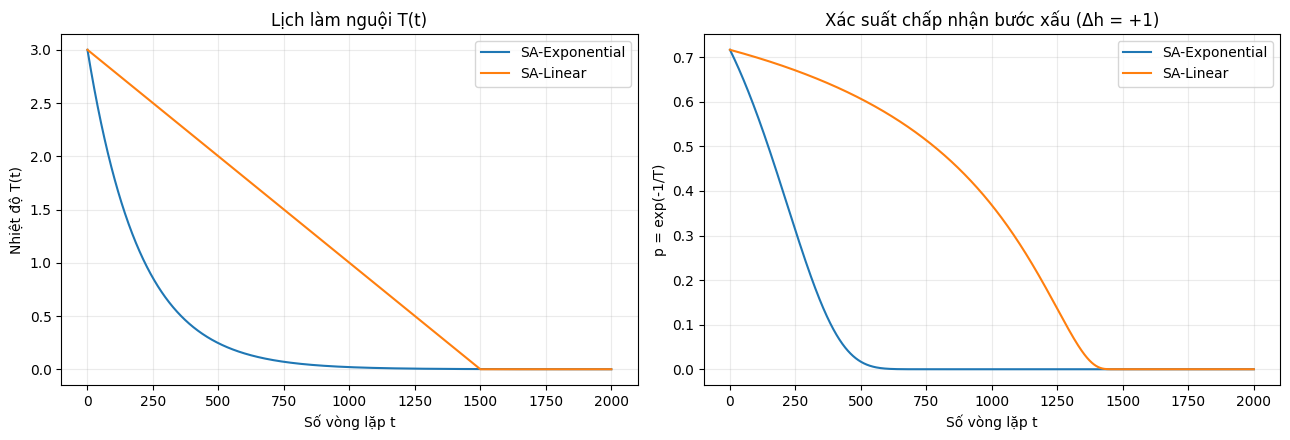

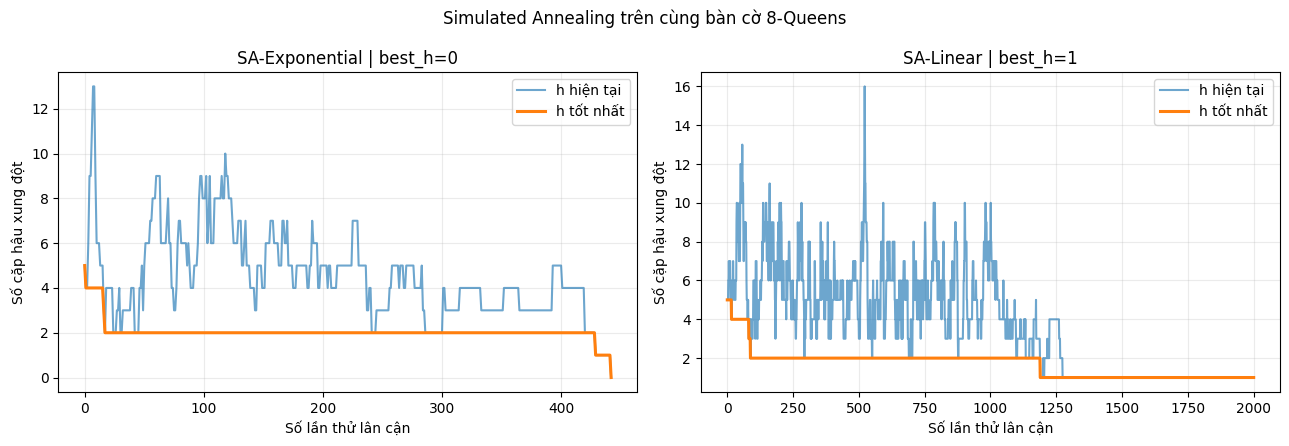

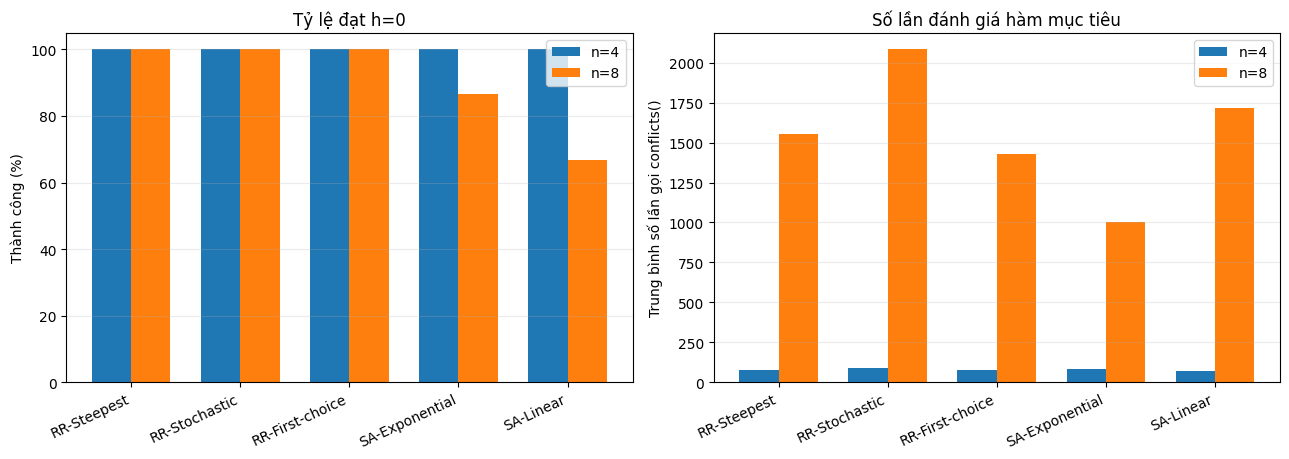

In [22]:
# Hình 1: Xác suất và nhiệt độ hai lịch làm nguội (cùng T0 = 3).
points = np.arange(0, 2001)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, schedule in SA_SCHEDULES_B7:
    temps = np.asarray([annealing_temperature(t, schedule, 3, .995, .002) for t in points])
    axes[0].plot(points, temps, label=name)
    acceptance = np.where(temps > 0, np.exp(-1 / np.maximum(temps, 1e-300)), 0.0)
    axes[1].plot(points, acceptance, label=name)
axes[0].set(title='Lịch làm nguội T(t)', xlabel='Số vòng lặp t', ylabel='Nhiệt độ T(t)')
axes[1].set(title='Xác suất chấp nhận bước xấu (Δh = +1)', xlabel='Số vòng lặp t', ylabel='p = exp(-1/T)')
for ax in axes: ax.grid(alpha=.25); ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR_B7/'Bai7_Cooling_Schedules.png', dpi=160, bbox_inches='tight')
plt.show()

# Hình 2: SA trạng thái hiện tại và nghiệm tốt nhất, n=8 (một lượt đại diện).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, _) in zip(axes, SA_SCHEDULES_B7):
    r = demo_results_b7[8, name]
    ax.plot(r['history_current'], alpha=.65, label='h hiện tại')
    ax.plot(r['history_best'], linewidth=2.2, label='h tốt nhất')
    ax.set(title=f'{name} | best_h={r["final_h"]}', xlabel='Số lần thử lân cận', ylabel='Số cặp hậu xung đột')
    ax.grid(alpha=.25); ax.legend()
fig.suptitle('Simulated Annealing trên cùng bàn cờ 8-Queens')
fig.tight_layout()
fig.savefig(RESULT_DIR_B7/'Bai7_SA_Convergence.png', dpi=160, bbox_inches='tight')
plt.show()

# Hình 3: Tỷ lệ thành công và chi phí đánh giá trên 30 lượt/cấu hình.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
labels = algorithms_b7
x = np.arange(len(labels))
for i, n in enumerate((4,8)):
    data = summary_b7.set_index(['n','algorithm'])
    s = [data.loc[(n,a),'success_percent'] for a in labels]
    ev = [data.loc[(n,a),'mean_evaluations'] for a in labels]
    axes[0].bar(x + (i-.5)*.36, s, .36, label=f'n={n}')
    axes[1].bar(x + (i-.5)*.36, ev, .36, label=f'n={n}')
axes[0].set(title='Tỷ lệ đạt h=0', ylabel='Thành công (%)', ylim=(0,105))
axes[1].set(title='Số lần đánh giá hàm mục tiêu', ylabel='Trung bình số lần gọi conflicts()')
for ax in axes:
    ax.set_xticks(x, labels, rotation=25, ha='right')
    ax.grid(axis='y', alpha=.25); ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR_B7/'Bai7_Success_and_Evaluations.png', dpi=160, bbox_inches='tight')
plt.show()

### Bài 7 — Nhận xét và kết luận

1. **Random Restart** bắt đầu lại từ các trạng thái khác nhau để tăng cơ hội tìm được $h=0$. Trong lần chạy đầu không thành công, nó phải trả giá bằng tổng số lượt khởi động và số lần gọi hàm mục tiêu cao hơn. `RESTART_LIMIT` chỉ là kết quả hết ngân sách.
2. **Simulated Annealing** có thể chấp nhận nước đi làm tăng $h$, nhờ vậy vẫn thăm dò không gian tìm kiếm khi Hill Climbing chỉ nhận cải thiện đã dừng. `history_current` có thể dao động; `history_best` không bao giờ tăng và là kết quả dùng đánh giá chất lượng nghiệm.
3. **Hai lịch nhiệt** có cùng $T_0$ nhưng tốc độ giảm khác nhau. Lịch giữ nhiệt cao lâu hơn thường duy trì xác suất chấp nhận bước xấu lớn hơn; điều đó **không bảo đảm tỷ lệ thành công cao hơn** ở ngân sách hữu hạn. So sánh phải dựa vào cả `final_h`, tỷ lệ $h=0$, số lần đánh giá và thời gian chạy.
4. Thống kê 30 lượt/cấu hình ở Bài 7 nhằm minh họa và kiểm tra triển khai; **Task 6 ở Bài 8** sẽ tăng lên ít nhất 100 lượt mỗi thiết lập theo yêu cầu giảng viên. Không được đồng nhất `steps` của RR (cộng dồn số nước HC cải thiện) với `steps` của SA (mọi bước được chấp nhận, kể cả bước tệ hơn).

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

### Bài 8 – Task 6: thí nghiệm đối chứng 100 lượt/cấu hình

- Giữ nguyên mã Bài 5–7, so sánh **8 cấu hình**: ba Hill Climbing đơn lượt, ba Random Restart và hai Simulated Annealing.
- Với mỗi `n = 4, 8`, tạo **100 bàn cờ khởi tạo khác nhau** từ seed `20261020 + 800`. Cùng `(n, trial)` thì mọi phương pháp sử dụng đúng **một board**; seed thuật toán được tách để tái lập lựa chọn ngẫu nhiên.
- `solved` khi và chỉ khi `final_h=0`; `final_h` với SA/RR là **nghiệm tốt nhất từng gặp**, còn HC là trạng thái dừng. `evaluations` ghi số lần gọi `conflicts()` bên trong thuật toán, **không tính** xác minh lại từ cell báo cáo.
- Ngân sách: HC tối đa 1.000 bước cải thiện, RR tối đa **100 lần restart sau lượt đầu**, SA tối đa **2.000 lần sinh láng giềng**. Các ngân sách **khác nhau** nên không khẳng định so sánh thành công hoàn toàn công bằng theo số evaluation.
- Thống kê mean, median thời gian `perf_counter` (ms), mean `final_h`, thành công (%), số đánh giá và các CSV raw để tái hiện. Tỷ lệ thành công luôn tính trên **100 lượt**, không tính từng restart là một lượt độc lập.

Task 6 hoàn thành: 1600 lượt = 2 kích thước × 8 thuật toán × 100 board; seed=20261020.


,n,algorithm,runs,successes,success_percent,mean_final_h,mean_evaluations,mean_ms,median_ms
0,4,First-choice,100,27,27.0,0.94,36.72,0.485,0.348
1,4,RR-First-choice,100,100,100.0,0.00,116.72,3.100,0.973
2,4,RR-Steepest,100,100,100.0,0.00,64.39,0.514,0.328
3,4,RR-Stochastic,100,100,100.0,0.00,102.75,2.152,0.614
4,4,SA-Exponential,100,100,100.0,0.00,77.21,1.199,0.811
5,4,SA-Linear,100,100,100.0,0.00,99.49,1.366,0.807
6,4,Steepest-ascent,100,38,38.0,0.71,26.92,0.182,0.131
7,4,Stochastic (all),100,34,34.0,0.81,31.12,0.223,0.159
8,8,First-choice,100,11,11.0,1.32,212.23,2.781,2.544
9,8,RR-First-choice,100,100,100.0,0.00,1904.01,25.779,18.192


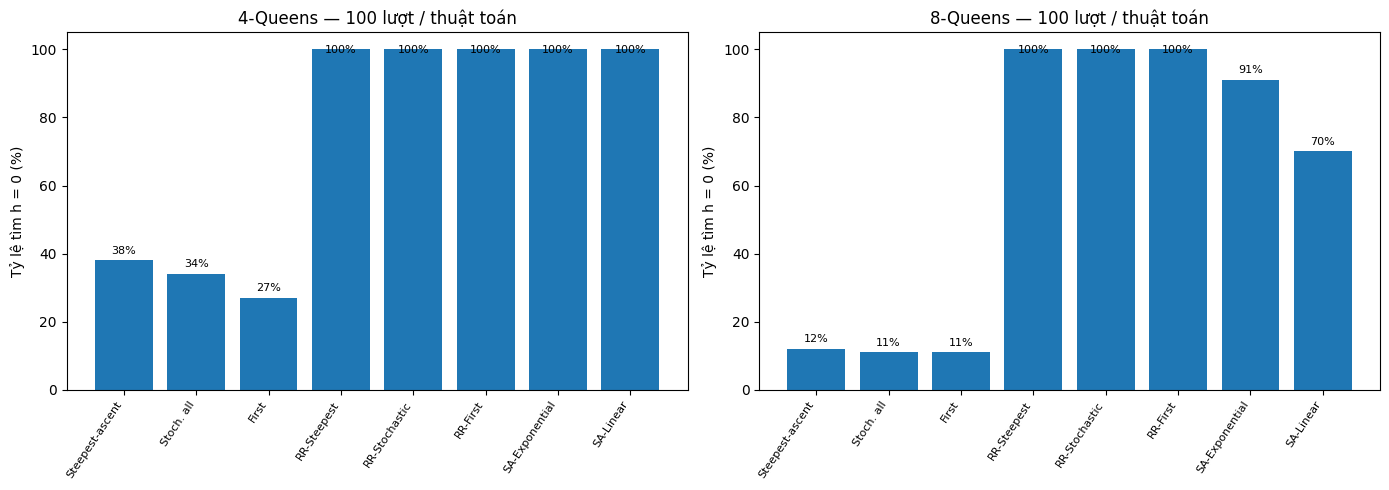

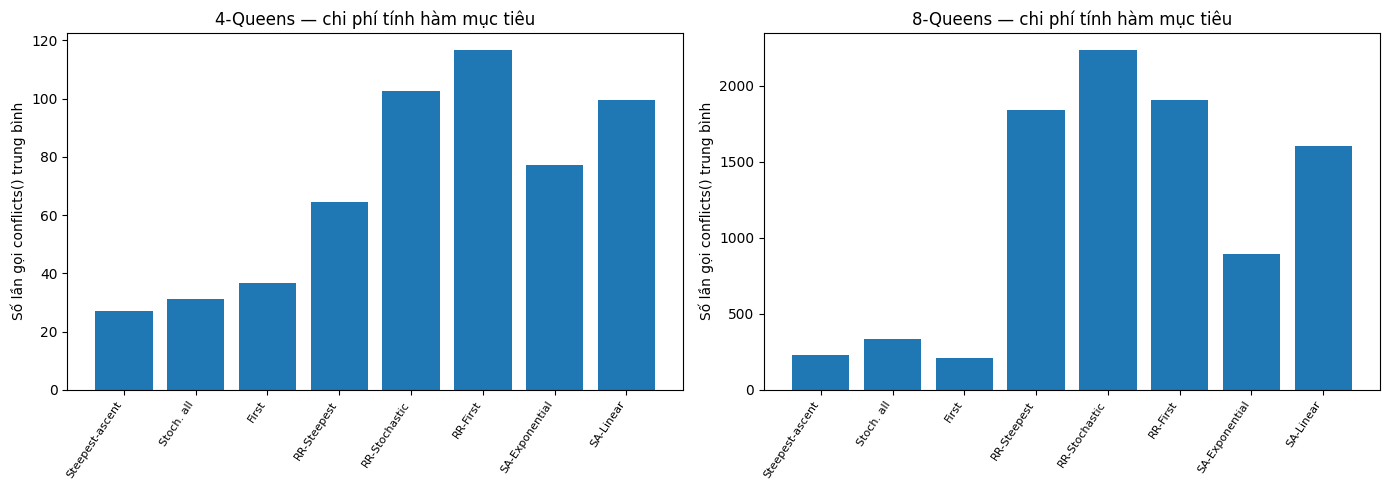

In [23]:
# Bài 8 — Task 6: ít nhất 100 lượt / thuật toán / kích thước.
from pathlib import Path
from time import perf_counter
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR_B8 = Path('Lab04_Bai8_Results')
RESULT_DIR_B8.mkdir(parents=True, exist_ok=True)
SEED_B8 = 20261020
N_TRIALS_B8 = 100

# Dùng CHUNG các board khởi tạo theo (n, trial), cố định seed; seed thuật toán tách biệt.
algorithms_b8 = ['Steepest-ascent', 'Stochastic (all)', 'First-choice',
                 'RR-Steepest', 'RR-Stochastic', 'RR-First-choice',
                 'SA-Exponential', 'SA-Linear']

def run_b8(board, method, seed, *, sa_limit=2000, rr_limit=100):
    """Cùng đầu vào; giới hạn và cơ chế tìm kiếm của từng phương pháp được ghi riêng."""
    if method == 'Steepest-ascent':
        return steepest_ascent(board, max_steps=1000)
    if method == 'Stochastic (all)':
        return inefficient_stochastic(board, seed=seed, max_steps=1000)
    if method == 'First-choice':
        return efficient_stochastic(board, seed=seed, max_steps=1000)
    if method.startswith('RR-'):
        key = {'RR-Steepest':'steepest','RR-Stochastic':'stochastic',
               'RR-First-choice':'first_choice'}[method]
        return random_restart_hill_climbing(board, method=key, seed=seed,
                                          max_restarts=rr_limit, max_steps=1000)
    return simulated_annealing_queens(board, seed=seed,
             schedule={'SA-Exponential':'exponential','SA-Linear':'linear'}[method],
             T0=3.0, alpha=0.995, eta=0.002, max_iterations=sa_limit)

rng_b8 = np.random.default_rng(SEED_B8 + 800)
def unique_initial_boards_b8(n, count, rng):
    """Sinh count bàn cờ phân biệt (n=4 có 256 cấu hình, tránh lặp ngẫu nhiên)."""
    boards, seen = [], set()
    while len(boards) < count:
        board = rng.integers(0,n,size=n,dtype=np.int64)
        key = tuple(int(v) for v in board)
        if key not in seen:
            seen.add(key)
            boards.append(board)
    return boards
start_boards_b8 = {n:unique_initial_boards_b8(n,N_TRIALS_B8,rng_b8) for n in (4,8)}
assert all(len({tuple(b) for b in starts})==N_TRIALS_B8 for starts in start_boards_b8.values())
rows_b8 = []
for n in (4,8):
    for trial,board in enumerate(start_boards_b8[n]):
        board_snapshot = board.copy()
        for ai,algo in enumerate(algorithms_b8):
            seed = SEED_B8 + n*1000000 + trial*100 + ai
            r = run_b8(board, algo, seed)
            assert np.array_equal(board, board_snapshot), 'Thuật toán làm đổi input'
            assert r['final_h'] == int(conflicts(r['board']))
            assert (r['final_h']==0) == r['solved']
            assert r['evaluations'] >= 1 and r['steps'] >= 0
            rows_b8.append(dict(n=n, trial=trial+1, seed=seed, algorithm=algo,
                       initial_h=int(conflicts(board)), final_h=int(r['final_h']),
                       solved=bool(r['solved']), status=r['status'],
                       steps=int(r['steps']), evaluations=int(r['evaluations']),
                       elapsed_ms=float(r['elapsed_ms']),
                       runs=int(r.get('runs',1)), restarts=int(r.get('restarts_used',0)),
                       accepted_worse=int(r.get('accepted_worse',0))))

trials_b8=pd.DataFrame(rows_b8)
assert len(trials_b8)==2*N_TRIALS_B8*len(algorithms_b8)
assert (trials_b8.groupby(['n','algorithm']).size()==N_TRIALS_B8).all()
summary_b8=(trials_b8.groupby(['n','algorithm'],as_index=False)
  .agg(runs=('solved','size'),successes=('solved','sum'),
       success_rate=('solved','mean'),mean_initial_h=('initial_h','mean'),
       mean_final_h=('final_h','mean'),median_final_h=('final_h','median'),
       mean_steps=('steps','mean'),mean_evaluations=('evaluations','mean'),
       mean_ms=('elapsed_ms','mean'),median_ms=('elapsed_ms','median'),
       mean_restarts=('restarts','mean')))
summary_b8['success_percent']=100*summary_b8['success_rate']
trials_b8.to_csv(RESULT_DIR_B8/'Bai8_Task6_Trials.csv',index=False,encoding='utf-8-sig')
summary_b8.to_csv(RESULT_DIR_B8/'Bai8_Task6_Summary.csv',index=False,encoding='utf-8-sig')
print(f'Task 6 hoàn thành: {len(trials_b8)} lượt = 2 kích thước × 8 thuật toán × 100 board; seed={SEED_B8}.')
display(summary_b8[['n','algorithm','runs','successes','success_percent','mean_final_h',
                    'mean_evaluations','mean_ms','median_ms']].round(3))

# Ảnh bảng chính: thành công và thời gian — đúng phạm vi n=4,8, không thay thế CSV.
fig,ax=plt.subplots(1,2,figsize=(14,5))
for j,n in enumerate((4,8)):
    s=summary_b8[summary_b8.n==n].set_index('algorithm').loc[algorithms_b8]
    ax[j].bar(range(len(s)),s.success_percent)
    ax[j].set_title(f'{n}-Queens — {N_TRIALS_B8} lượt / thuật toán')
    ax[j].set_ylabel('Tỷ lệ tìm h = 0 (%)')
    ax[j].set_ylim(0,105)
    ax[j].set_xticks(range(len(s)))
    ax[j].set_xticklabels([a.replace('Stochastic (all)','Stoch. all').replace('First-choice','First')
                            for a in s.index],rotation=56,ha='right',fontsize=8)
    for i,v in enumerate(s.success_percent):
        ax[j].text(i,min(99,v+2),f'{v:.0f}%',ha='center',fontsize=8)
fig.tight_layout()
fig.savefig(RESULT_DIR_B8/'Bai8_Task6_Success_Rates.png',dpi=170,bbox_inches='tight')
plt.show()

fig,ax=plt.subplots(1,2,figsize=(14,5))
for j,n in enumerate((4,8)):
    s=summary_b8[summary_b8.n==n].set_index('algorithm').loc[algorithms_b8]
    ax[j].bar(range(len(s)),s.mean_evaluations)
    ax[j].set_title(f'{n}-Queens — chi phí tính hàm mục tiêu')
    ax[j].set_ylabel('Số lần gọi conflicts() trung bình')
    ax[j].set_xticks(range(len(s)))
    ax[j].set_xticklabels([a.replace('Stochastic (all)','Stoch. all').replace('First-choice','First')
                            for a in s.index],rotation=56,ha='right',fontsize=8)
fig.tight_layout()
fig.savefig(RESULT_DIR_B8/'Bai8_Task6_Evaluations.png',dpi=170,bbox_inches='tight')
plt.show()


### Bài 8 – Nhận xét sau 100 lượt/cấu hình

Dữ liệu thực tế từ `Bai8_Task6_Summary.csv` (100 trạng thái **phân biệt** cho mỗi n, tám thuật toán trên cùng từng trạng thái):

|   n | algorithm        |   success_percent |   mean_final_h |   mean_evaluations |   mean_ms |
|----:|:-----------------|------------------:|---------------:|-------------------:|----------:|
|   4 | First-choice     |                27 |           0.94 |              36.72 |      0.49 |
|   4 | RR-First-choice  |               100 |           0    |             116.72 |      3.1  |
|   4 | RR-Steepest      |               100 |           0    |              64.39 |      0.51 |
|   4 | RR-Stochastic    |               100 |           0    |             102.75 |      2.15 |
|   4 | SA-Exponential   |               100 |           0    |              77.21 |      1.2  |
|   4 | SA-Linear        |               100 |           0    |              99.49 |      1.37 |
|   4 | Steepest-ascent  |                38 |           0.71 |              26.92 |      0.18 |
|   4 | Stochastic (all) |                34 |           0.81 |              31.12 |      0.22 |
|   8 | First-choice     |                11 |           1.32 |             212.23 |      2.78 |
|   8 | RR-First-choice  |               100 |           0    |            1904.01 |     25.78 |
|   8 | RR-Steepest      |               100 |           0    |            1840.43 |     16.32 |
|   8 | RR-Stochastic    |               100 |           0    |            2237.35 |     21.95 |
|   8 | SA-Exponential   |                91 |           0.09 |             890.71 |     13.03 |
|   8 | SA-Linear        |                70 |           0.3  |            1606.21 |     22.35 |
|   8 | Steepest-ascent  |                12 |           1.31 |             230.04 |      1.92 |
|   8 | Stochastic (all) |                11 |           1.31 |             334.2  |      3    |

Tỷ lệ thành công 100% của ba biến thể Random Restart chỉ đúng **trong bộ 100 lần thử và ngân sách tối đa 100 restart** này, không phải bảo đảm thuật toán chắc chắn thành công. Với n=8, kết quả Hill Climbing đơn lượt thấp hơn rõ rệt; nếu đạt `LOCAL_MINIMUM`, đã khảo sát tất cả láng giềng (theo toán tử gốc) mà không có cải thiện. Với `TRY_LIMIT` của First-choice, chưa thể kết luận không tồn tại láng giềng tốt hơn. Simulated Annealing đôi khi chấp nhận bước tệ hơn, nhưng chỉ lưu kết quả `best_h`, không đồng nhất với `current_h`.

Do ngân sách của các thuật toán khác nhau, bảng này mô tả **chất lượng so với chi phí đo được**, không phải so sánh ngang ngân sách đánh giá. Thời gian có thể biến động theo môi trường và tình trạng tải máy.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

### Bài 8 – Diễn giải đồ thị hội tụ

Đồ thị minh họa **một lần chạy trên cùng bàn cờ 8-Queens**; mỗi đường lưu `h` tốt nhất không tăng. Steepest/Stochastic/First-choice dùng chỉ số **bước cải thiện được chấp nhận**; Random Restart dùng **lượt tìm kiếm con**; Simulated Annealing dùng **lần thử láng giềng**. Vì trục ngang không đồng nhất, đồ thị dùng để minh họa xu hướng, **không** để suy ra thuật toán nào hội tụ nhanh hơn theo cùng số evaluations hoặc theo thời gian. HC có thể dừng tại `LOCAL_MINIMUM`/`TRY_LIMIT` trước khi `h=0`; SA có thể có plateau của **best_h** dù `current_h` dao động.

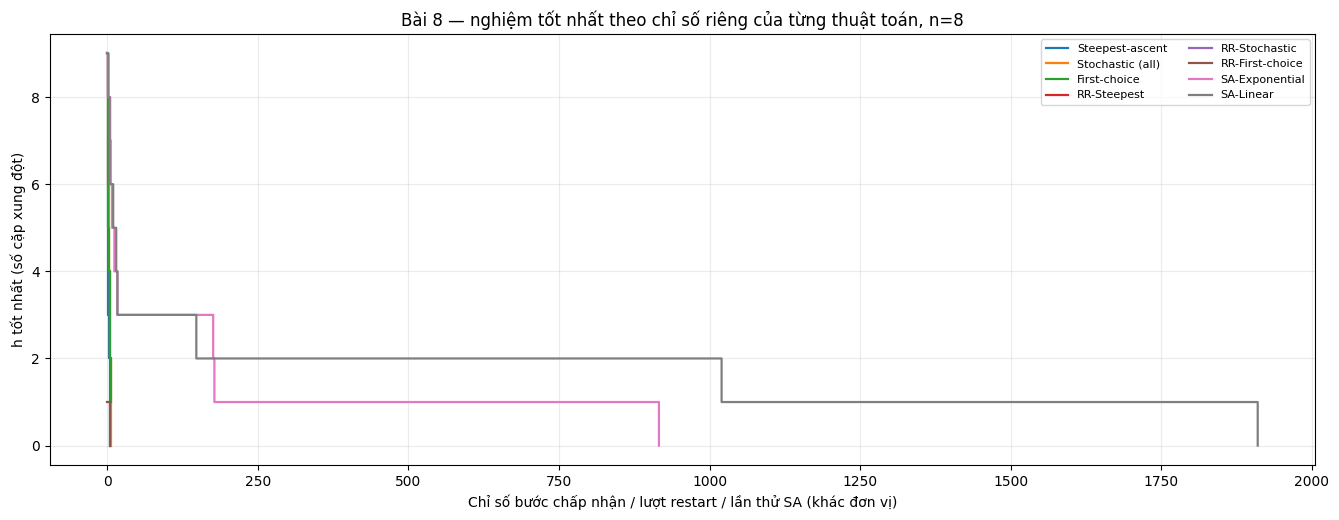

Bàn cờ n=8 dùng để so sánh hội tụ: [4, 0, 2, 1, 5, 1, 1, 1] ; h ban đầu = 9
Steepest-ascent   : h cuối=0, trạng thái=SOLVED, bước=5, đánh giá=281
Stochastic (all)  : h cuối=0, trạng thái=SOLVED, bước=7, đánh giá=393
First-choice      : h cuối=1, trạng thái=TRY_LIMIT, bước=6, đánh giá=230
RR-Steepest       : h cuối=0, trạng thái=SOLVED, bước=5, đánh giá=281
RR-Stochastic     : h cuối=0, trạng thái=SOLVED, bước=6, đánh giá=337
RR-First-choice   : h cuối=0, trạng thái=SOLVED, bước=24, đánh giá=1287
SA-Exponential    : h cuối=0, trạng thái=SOLVED, bước=248, đánh giá=917
SA-Linear         : h cuối=0, trạng thái=SOLVED, bước=831, đánh giá=1911


In [24]:
# Task 6 — biểu đồ hội tụ n=8, cùng trạng thái khởi tạo.
# CHÚ Ý: đơn vị trục ngang phụ thuộc thuật toán, KHÔNG so sánh trực tiếp tốc độ theo x.
convergence_board_b8 = np.asarray(start_boards_b8[8][0],dtype=np.int64)
convergence_b8={}
convergence_rows_b8=[]
for ai,algo in enumerate(algorithms_b8):
    r=run_b8(convergence_board_b8,algo,SEED_B8+88800+ai)
    convergence_b8[algo]=r
    history = r.get('history_best',r['history'])
    assert all(history[k]>=history[k+1] for k in range(len(history)-1))
    for t,h in enumerate(history):
        convergence_rows_b8.append(dict(algorithm=algo, index=t, best_h=int(h),
            index_definition=('lượt khởi động' if algo.startswith('RR-') else
                              'lần thử nước đi' if algo.startswith('SA-') else
                              'bước cải thiện được chấp nhận')))
convergence_df_b8=pd.DataFrame(convergence_rows_b8)
convergence_df_b8.to_csv(RESULT_DIR_B8/'Bai8_Convergence_Representative_n8.csv',
                         index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(13.5,5.3))
for name in algorithms_b8:
    d=convergence_df_b8[convergence_df_b8.algorithm==name]
    ax.step(d['index'],d['best_h'],where='post',label=name,linewidth=1.6)
ax.set_title('Bài 8 — nghiệm tốt nhất theo chỉ số riêng của từng thuật toán, n=8')
ax.set_xlabel('Chỉ số bước chấp nhận / lượt restart / lần thử SA (khác đơn vị)')
ax.set_ylabel('h tốt nhất (số cặp xung đột)')
ax.grid(alpha=.25); ax.legend(ncol=2,fontsize=8)
fig.tight_layout()
fig.savefig(RESULT_DIR_B8/'Bai8_Convergence_n8.png',dpi=170,bbox_inches='tight')
plt.show()
print('Bàn cờ n=8 dùng để so sánh hội tụ:',convergence_board_b8.tolist(),
      '; h ban đầu =',int(conflicts(convergence_board_b8)))
for name in algorithms_b8:
    r=convergence_b8[name]
    print(f"{name:18s}: h cuối={r['final_h']}, trạng thái={r['status']}, "
          f"bước={r['steps']}, đánh giá={r['evaluations']}")


### Bài 8 – Nhận xét hội tụ

Steepest thường làm giảm `h` mạnh ngay những bước đầu vì quét toàn bộ lân cận, nhưng có thể dừng sớm ở local optimum. Stochastic và First-choice chỉ chấp nhận bước cải thiện nên `h` trong lịch sử của chúng giảm nghiêm ngặt khi có bước di chuyển; khi hết bước cải thiện hoặc hết ngân sách thử, đường hội tụ dừng trên plateau của lịch sử. Random Restart có thể vượt cực tiểu cục bộ bằng cách thay điểm bắt đầu; đường `best_h` duy trì hoặc giảm theo số lượt restart. Với Simulated Annealing, `current_h` có thể tăng vì đôi lúc chấp nhận bước xấu, còn đường `best_h` không tăng; plateau trên đường `best_h` chỉ có nghĩa tạm thời chưa ghi nhận được nghiệm tốt hơn.

**Không đọc trực tiếp vị trí trên trục x để kết luận tốc độ** vì bước chấp nhận, lượt restart và lượt thử là ba đơn vị khác nhau. Hãy sử dụng `evaluations` và `elapsed_ms` của Task 6 khi so sánh chi phí.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

### Bài 8 – Đánh giá khả năng mở rộng

Chạy lặp **25 lượt ở mỗi kích thước** `n ∈ {4, 8, 12, 16, 20}`, cùng board giữa Steepest-ascent, First-choice và SA-Exponential tại từng lượt. Riêng thí nghiệm mở rộng, SA dùng ngân sách cố định **500 lần thử** để thời gian có thể đối chiếu theo n; đây là một thiết lập **khác** Task 6. Vẽ log-log **trung vị** thời gian chạy, ước lượng độ dốc bằng hồi quy trên `log(n)` và `log(time)`.

**Không đồng nhất hệ số dốc đo được với định lý Big-O.** Thời gian đo phụ thuộc Python/NumPy, điều kiện dừng sớm, ngân sách cố định, số bước thực hiện và cấu trúc board; kiểm tra độ phức tạp lý thuyết cần phân tích số láng giềng và chi phí tính `conflicts()`.

Steepest-ascent độ dốc log-log thực nghiệm ≈ 3.999
First-choice độ dốc log-log thực nghiệm ≈ 3.02
SA-Exponential độ dốc log-log thực nghiệm ≈ 1.748


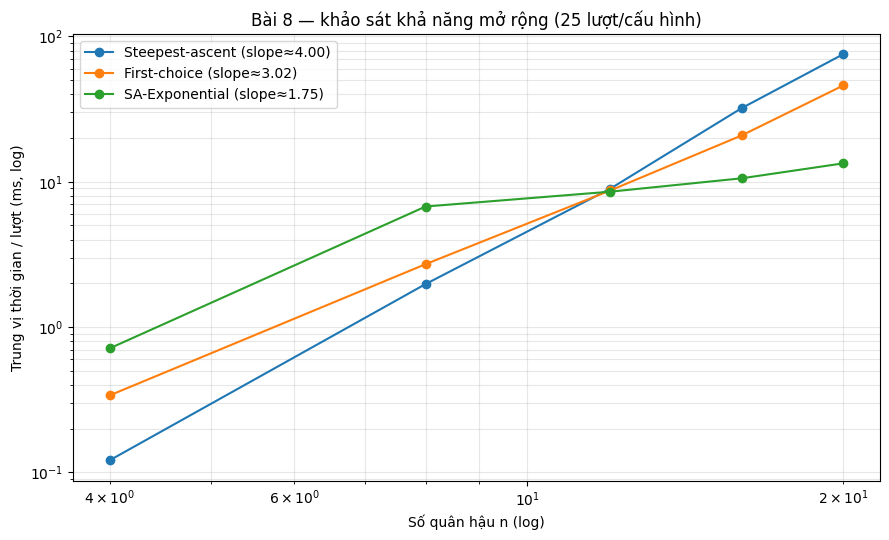

,n,algorithm,runs,median_ms,mean_evaluations,mean_final_h
0,4,First-choice,25,0.338,36.20,0.84
1,4,SA-Exponential,25,0.713,103.84,0.00
2,4,Steepest-ascent,25,0.121,27.88,0.60
3,8,First-choice,25,2.710,204.92,1.12
4,8,SA-Exponential,25,6.756,481.84,0.88
5,8,Steepest-ascent,25,1.977,229.48,1.20
6,12,First-choice,25,8.726,525.96,1.88
7,12,SA-Exponential,25,8.548,501.00,2.16
8,12,Steepest-ascent,25,8.978,745.48,2.08
9,16,First-choice,25,20.831,1028.76,2.32


In [25]:
# Task 6 — log-log với n={4,8,12,16,20}.
# Một batch đo riêng, thống nhất board theo (n,trial), 25 lượt/cấu hình.
# SA dùng 500 lần thử trên mọi n; chỉ kiểm tra xu hướng với ngân sách cố định,
# KHÔNG suy độ phức tạp Big-O từ hệ số dốc của số liệu đo.
SIZES_B8=(4,8,12,16,20)
SCALE_TRIALS_B8=25
SCALE_ALGOS_B8=['Steepest-ascent','First-choice','SA-Exponential']
rng_scale_b8=np.random.default_rng(SEED_B8+811)
scale_rows_b8=[]
for n in SIZES_B8:
    boards=[rng_scale_b8.integers(0,n,size=n,dtype=np.int64)
            for _ in range(SCALE_TRIALS_B8)]
    for trial,board in enumerate(boards):
        for ai,algo in enumerate(SCALE_ALGOS_B8):
            r=run_b8(board,algo,seed=SEED_B8+n*10000+trial*10+ai,sa_limit=500)
            scale_rows_b8.append(dict(n=n,trial=trial+1,algorithm=algo,
                      final_h=r['final_h'],solved=r['solved'],
                      evaluations=r['evaluations'],elapsed_ms=r['elapsed_ms']))
scale_trials_b8=pd.DataFrame(scale_rows_b8)
scale_b8=(scale_trials_b8.groupby(['n','algorithm'],as_index=False)
          .agg(runs=('solved','size'),success_rate=('solved','mean'),
               median_ms=('elapsed_ms','median'),mean_ms=('elapsed_ms','mean'),
               mean_evaluations=('evaluations','mean'),mean_final_h=('final_h','mean')))
scale_trials_b8.to_csv(RESULT_DIR_B8/'Bai8_Scalability_Trials.csv',index=False,encoding='utf-8-sig')
scale_b8.to_csv(RESULT_DIR_B8/'Bai8_Scalability_Summary.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(9,5.5))
for name in SCALE_ALGOS_B8:
    d=scale_b8[scale_b8.algorithm==name].sort_values('n')
    xx=d.n.to_numpy(dtype=float)
    yy=d.median_ms.to_numpy(dtype=float)
    valid=(yy>0)&np.isfinite(yy)
    slope=float(np.polyfit(np.log(xx[valid]),np.log(yy[valid]),1)[0])
    ax.loglog(xx,yy,'-o',label=f'{name} (slope≈{slope:.2f})')
    print(name,'độ dốc log-log thực nghiệm ≈',round(slope,3))
ax.set_xlabel('Số quân hậu n (log)')
ax.set_ylabel('Trung vị thời gian / lượt (ms, log)')
ax.set_title('Bài 8 — khảo sát khả năng mở rộng (25 lượt/cấu hình)')
ax.grid(True,which='both',alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR_B8/'Bai8_Scalability_LogLog.png',dpi=170,bbox_inches='tight')
plt.show()
display(scale_b8[['n','algorithm','runs','median_ms','mean_evaluations','mean_final_h']].round(3))


### Bài 8 – Thảo luận khả năng mở rộng

Độ dốc từ hồi quy trên trung vị thời gian của năm kích thước trong lần đo này: First-choice: 3.02, SA-Exponential: 1.75, Steepest-ascent: 4.00. Đây là độ dốc **thực nghiệm trong khoảng n = 4–20**, không được khẳng định là độ phức tạp Big-O của thuật toán. Với `conflicts()` gốc được triển khai bằng bộ đếm O(n), một vòng quét đầy đủ n(n−1) láng giềng của Steepest cần đến O(n³) phép xử lý trong cách tính lại nguyên bàn cờ; First-choice thử từng láng giềng, còn số lần thử phụ thuộc xác suất gặp bước cải thiện và ngưỡng dừng. SA được cấp tối đa 500 lần thử nên xét riêng chi phí mỗi vòng và điều kiện dừng sớm; không so sánh số đo này trực tiếp với Task 6 có 2.000 lần thử.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

### Bài 8 – Advanced Task (bonus): toán tử thay thế

Triển khai và chạy First-choice với 5 toán tử: `random-row` (gốc), `single-step` (đi ±1 hàng không quay vòng), `column-swap` (đổi vị trí hàng của hai cột), `dual-queen` (đổi hai hậu đồng thời), `adaptive` (ưu tiên hậu xung đột cao, chọn random-row hoặc dual-queen). Giữ nguyên ràng buộc một hậu/cột, chấp nhận **chỉ bước giảm h**, lấy mẫu có hoàn lại.

Tại `n=8,12`, mỗi toán tử chạy 100 board chung mỗi kích thước. Ngân sách đánh giá chung giữa các toán tử ở mỗi n: tối đa 400 lần thử tại n=8, 700 lần thử tại n=12; giới hạn thất bại liên tiếp lần lượt 120 và 250. Các giới hạn này là lựa chọn **bổ sung cho bonus**, không phải tham số bắt buộc do giảng viên chỉ định.

`column-swap` giữ **nguyên multiset các hàng**: nếu đầu vào có hai hậu cùng hàng thì **không thể** đạt nghiệm h=0 chỉ với toán tử này; những Swap của hai hậu trùng hàng thậm chí không tạo trạng thái mới. `dual-queen` và `adaptive` có thể đổi hai vị trí nên không còn cùng tập lân cận một-bước như toán tử gốc. Giá trị trung bình thời gian thành công chỉ tính trên các lần thành công; nếu không có lượt thành công sẽ báo N/A, không gán 0 ms.

,n,operator,trials,successful,success_percent,mean_final_h,mean_evaluations,mean_ms,mean_success_ms
0,8,adaptive,100,22,22.0,1.10,128.21,5.922,2.374
1,8,column-swap,100,0,0.0,4.58,145.95,2.958,NaN
2,8,dual-queen,100,3,3.0,1.68,183.92,4.572,2.220
3,8,random-row,100,12,12.0,1.43,163.03,2.144,1.443
4,8,single-step,100,0,0.0,3.40,141.91,1.907,NaN
5,12,adaptive,100,5,5.0,1.52,316.50,20.613,10.474
6,12,column-swap,100,0,0.0,6.50,319.51,7.657,NaN
7,12,dual-queen,100,0,0.0,2.43,424.90,12.117,NaN
8,12,random-row,100,2,2.0,1.99,381.17,7.432,3.655
9,12,single-step,100,0,0.0,5.22,299.45,5.104,NaN


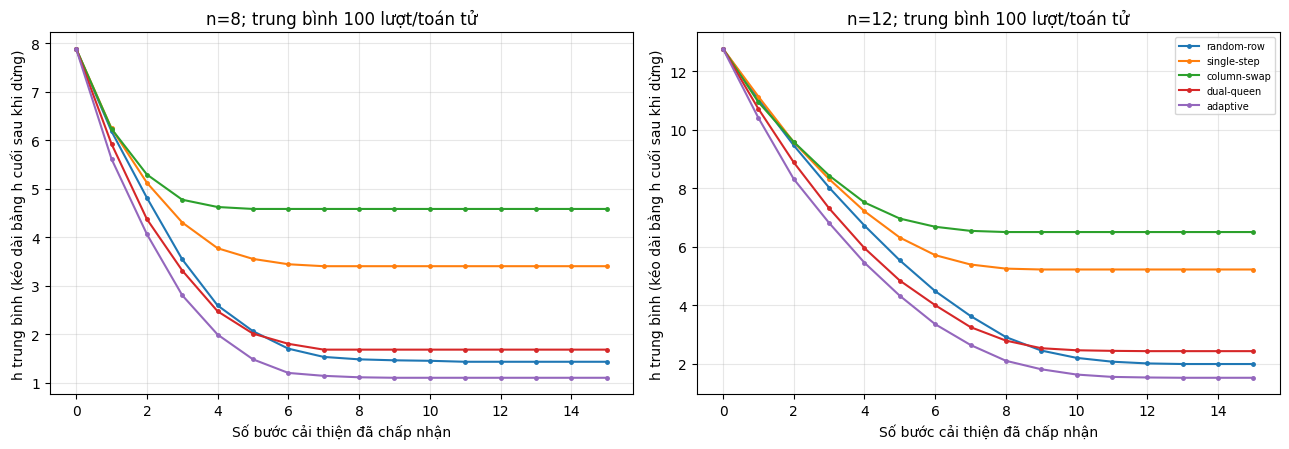

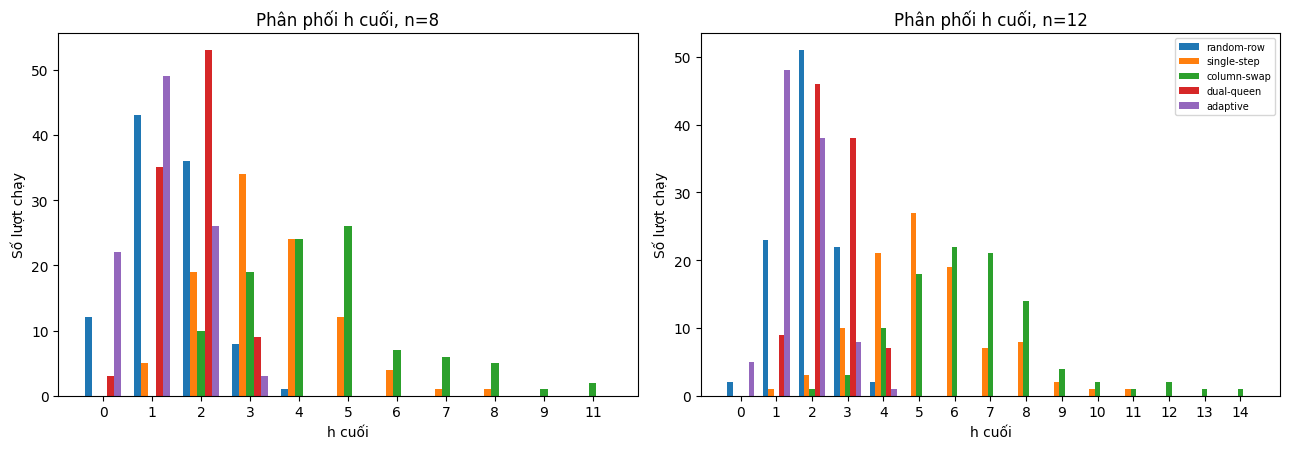

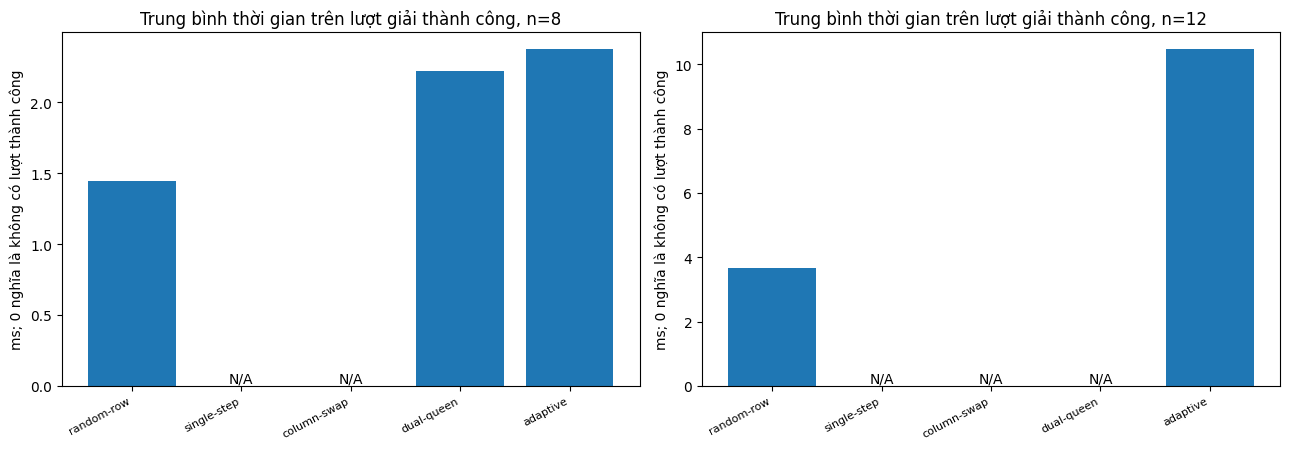

Advanced Task: 1000 lượt = 2 kích thước × 5 toán tử × 100 bàn cờ, hoàn tất.


In [26]:
# Advanced (bonus) — năm toán tử lân cận và First-choice với ngân sách hữu hạn.
# Thống nhất 100 board / n / operator tại n=8,12, tránh trộn bảng này với Task 6.
from math import comb

ADV_OPERATORS_B8=('random-row','single-step','column-swap','dual-queen','adaptive')
ADV_TRIALS_B8=100
ADV_SIZES_B8=(8,12)

def queen_conflict_degree_b8(board):
    """Số quân tấn công mỗi quân, sử dụng cho adaptive (không gọi conflicts())."""
    n=len(board)
    degrees=np.zeros(n,dtype=np.int64)
    for i in range(n):
        for j in range(i+1,n):
            if (board[i]==board[j] or abs(int(board[i])-int(board[j]))==j-i):
                degrees[i]+=1
                degrees[j]+=1
    return degrees


def advanced_neighbor_b8(board, op, rng):
    """Trả một phép di chuyển; không sửa board gốc; mỗi cột vẫn có một quân hậu."""
    n=len(board)
    cand=board.copy()
    if op=='random-row':
        return random_local_neighbor(board,rng)[2]
    if op=='single-step':
        col=int(rng.integers(n))
        row=int(board[col])
        options=[v for v in (row-1,row+1) if 0<=v<n]
        cand[col]=options[int(rng.integers(len(options)))]
        return cand
    if op=='column-swap':
        cols=rng.choice(n,size=2,replace=False)
        a,b=map(int,cols)
        cand[a],cand[b]=cand[b],cand[a]
        return cand
    if op=='dual-queen':
        cols=rng.choice(n,size=2,replace=False)
        for cc in cols:
            col=int(cc); old=int(board[col])
            cand[col]=(old+int(rng.integers(1,n)))%n
        return cand
    if op=='adaptive':
        degrees=queen_conflict_degree_b8(board)
        candidates=np.flatnonzero(degrees==max(degrees))
        col=int(rng.choice(candidates))
        if rng.random()<0.75:
            cand[col]=(int(board[col])+int(rng.integers(1,n)))%n
        else:
            others=np.array([j for j in range(n) if j != col])
            other=int(rng.choice(others))
            cand[col]=(int(board[col])+int(rng.integers(1,n)))%n
            cand[other]=(int(board[other])+int(rng.integers(1,n)))%n
        return cand
    raise ValueError('Toán tử không hợp lệ: '+str(op))


def first_choice_operator_b8(board, operator, seed, max_attempts=None, failure_limit=None):
    """Một ứng viên/lần; chỉ nhận h giảm; so sánh 5 toán tử theo ngân sách chung."""
    rng=np.random.default_rng(seed)
    current=_valid_board_b6(board)
    n=len(current)
    if max_attempts is None: max_attempts=400 if n==8 else 700
    if failure_limit is None: failure_limit=120 if n==8 else 250
    start=perf_counter()
    current_h=int(conflicts(current)); evals=1; accepted=attempts=0
    failures=0; history=[current_h]
    while current_h>0 and attempts<max_attempts and failures<failure_limit:
        new=advanced_neighbor_b8(current,operator,rng)
        candidate_h=int(conflicts(new)); evals+=1;attempts+=1
        if candidate_h<current_h:
            current=new;current_h=candidate_h
            accepted+=1;failures=0;history.append(current_h)
        else:
            failures+=1
    return dict(board=current,final_h=current_h,solved=(current_h==0),
                attempts=attempts,steps=accepted,evaluations=evals,history=history,
                status='SOLVED' if current_h==0 else 'TRY_LIMIT' if failures>=failure_limit else 'EVAL_LIMIT',
                elapsed_ms=(perf_counter()-start)*1000)

# Kiểm thử các toán tử và toàn vẹn board (đặc biệt single-step, column-swap).
rng_check_b8=np.random.default_rng(SEED_B8+3)
for n in ADV_SIZES_B8:
    original=rng_check_b8.integers(0,n,size=n,dtype=np.int64)
    for op in ADV_OPERATORS_B8:
        for _ in range(25):
            cand=advanced_neighbor_b8(original,op,rng_check_b8)
            assert np.all((0<=cand)&(cand<n)) and len(cand)==n
            assert np.array_equal(original,np.asarray(original))
            diff=np.count_nonzero(cand!=original)
            assert diff<=2 if op in ('dual-queen','adaptive','column-swap') else diff==1
            if op=='column-swap': assert sorted(cand.tolist())==sorted(original.tolist())
            if op=='single-step': assert np.abs(cand-original).sum()==1
# Lưu kích thước lân cận của từng phép di chuyển (giá trị lý thuyết / hiệu lực).
neighborhood_rows_b8=[]
for n in ADV_SIZES_B8:
    for op in ADV_OPERATORS_B8:
        formula={'random-row':f'{n}({n}-1)={n*(n-1)}',
          'single-step':f'giữa {n} và {2*n} (phụ thuộc hàng)',
          'column-swap':f'C({n},2)={comb(n,2)} (có thể tạo bản sao)',
          'dual-queen':f'C({n},2)×({n}-1)^2={comb(n,2)*(n-1)**2}',
          'adaptive':'phụ thuộc trạng thái và cách chọn cột'}[op]
        neighborhood_rows_b8.append(dict(n=n,operator=op,one_step_neighborhood=formula))
pd.DataFrame(neighborhood_rows_b8).to_csv(RESULT_DIR_B8/'Bai8_Advanced_Neighborhoods.csv',index=False,encoding='utf-8-sig')

# Cùng board đầu vào ở mỗi (n,trial) cho mọi operator; seed độc lập.
adv_rng_b8=np.random.default_rng(SEED_B8+850)
adv_rows_b8=[]; histories_b8=[]
for n in ADV_SIZES_B8:
    adv_boards=unique_initial_boards_b8(n,ADV_TRIALS_B8,adv_rng_b8)
    for trial,board in enumerate(adv_boards):
        for oi,op in enumerate(ADV_OPERATORS_B8):
            run=first_choice_operator_b8(board,op,seed=SEED_B8+n*100000+trial*10+oi)
            assert int(conflicts(run['board']))==run['final_h']
            assert len(run['history'])==run['steps']+1
            assert all(a>b for a,b in zip(run['history'],run['history'][1:]))
            adv_rows_b8.append(dict(n=n,trial=trial+1,operator=op,
                initial_h=int(conflicts(board)),final_h=run['final_h'],
                solved=run['solved'],status=run['status'],steps=run['steps'],
                evaluations=run['evaluations'],elapsed_ms=run['elapsed_ms']))
            for step,h in enumerate(run['history']):
                histories_b8.append(dict(n=n,trial=trial+1,operator=op,accepted_moves=step,h=h))
adv_trials_b8=pd.DataFrame(adv_rows_b8)
assert len(adv_trials_b8)==2*5*100
adv_summary_b8=(adv_trials_b8.groupby(['n','operator'],as_index=False)
    .agg(trials=('solved','size'),successful=('solved','sum'),
         success_rate=('solved','mean'),mean_final_h=('final_h','mean'),
         mean_evaluations=('evaluations','mean'),mean_ms=('elapsed_ms','mean'),
         median_ms=('elapsed_ms','median')))
adv_success_times_b8=(adv_trials_b8[adv_trials_b8.solved]
   .groupby(['n','operator'])['elapsed_ms'].mean().rename('mean_success_ms').reset_index())
adv_summary_b8=adv_summary_b8.merge(adv_success_times_b8,how='left',on=['n','operator'])
adv_summary_b8['success_percent']=100*adv_summary_b8['success_rate']
adv_trials_b8.to_csv(RESULT_DIR_B8/'Bai8_Advanced_Trials.csv',index=False,encoding='utf-8-sig')
adv_summary_b8.to_csv(RESULT_DIR_B8/'Bai8_Advanced_Summary.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(histories_b8).to_csv(RESULT_DIR_B8/'Bai8_Advanced_Convergence_Raw.csv',
                                index=False,encoding='utf-8-sig')
display(adv_summary_b8[['n','operator','trials','successful','success_percent',
                'mean_final_h','mean_evaluations','mean_ms','mean_success_ms']].round(3))

# Ba yêu cầu đồ họa: hội tụ trung bình, phân phối nghiệm cuối, thời gian thành công.
# Hồi quy lịch sử sau khi dừng: giữ nguyên h cuối để tránh bias khi chỉ còn những lượt dài.
MAX_ADV_STEP_B8=15
fig,axes=plt.subplots(1,2,figsize=(13,4.6),sharey=False)
for j,n in enumerate(ADV_SIZES_B8):
    for op in ADV_OPERATORS_B8:
        curves=[]
        for trial in range(1,ADV_TRIALS_B8+1):
            h=[v['h'] for v in histories_b8
                 if v['n']==n and v['trial']==trial and v['operator']==op]
            assert h
            curves.append([h[min(i,len(h)-1)] for i in range(MAX_ADV_STEP_B8+1)])
        axes[j].plot(range(MAX_ADV_STEP_B8+1),np.mean(curves,axis=0),'-o',ms=2.5,label=op)
    axes[j].set_title(f'n={n}; trung bình 100 lượt/toán tử')
    axes[j].set_xlabel('Số bước cải thiện đã chấp nhận')
    axes[j].set_ylabel('h trung bình (kéo dài bằng h cuối sau khi dừng)')
    axes[j].grid(alpha=.3)
axes[1].legend(fontsize=7)
fig.tight_layout();fig.savefig(RESULT_DIR_B8/'Bai8_Advanced_Convergence.png',dpi=170,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4.6))
for j,n in enumerate(ADV_SIZES_B8):
    g=adv_trials_b8[adv_trials_b8.n==n]
    cats=sorted(g.final_h.unique())
    x=np.arange(len(cats));w=0.15
    for oi,op in enumerate(ADV_OPERATORS_B8):
        cnt=g[g.operator==op].final_h.value_counts()
        axes[j].bar(x+(oi-2)*w,[cnt.get(h,0) for h in cats],width=w,label=op)
    axes[j].set_xticks(x);axes[j].set_xticklabels(cats)
    axes[j].set_xlabel('h cuối')
    axes[j].set_ylabel('Số lượt chạy')
    axes[j].set_title(f'Phân phối h cuối, n={n}')
axes[1].legend(fontsize=7)
fig.tight_layout();fig.savefig(RESULT_DIR_B8/'Bai8_Advanced_Final_H_Distribution.png',dpi=170,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4.6))
for j,n in enumerate(ADV_SIZES_B8):
    s=adv_summary_b8[adv_summary_b8.n==n].set_index('operator').loc[list(ADV_OPERATORS_B8)]
    ys=s.mean_success_ms.fillna(0)
    axes[j].bar(range(len(s)),ys)
    axes[j].set_xticks(range(len(s)))
    axes[j].set_xticklabels(s.index,rotation=28,ha='right',fontsize=8)
    axes[j].set_title(f'Trung bình thời gian trên lượt giải thành công, n={n}')
    axes[j].set_ylabel('ms; 0 nghĩa là không có lượt thành công')
    for oi,op in enumerate(s.index):
        if pd.isna(s.loc[op,'mean_success_ms']): axes[j].text(oi,0,'N/A',ha='center',va='bottom')
fig.tight_layout();fig.savefig(RESULT_DIR_B8/'Bai8_Advanced_Success_Time.png',dpi=170,bbox_inches='tight');plt.show()

# Kiểm chứng bất biến column-swap: nếu board có 2 hậu trùng hàng, mọi hoán vị cột giữ trùng hàng.
example_swap_b8=np.array([0,0,2,3,4,5,6,7],dtype=np.int64)
assert len(np.unique(example_swap_b8))<len(example_swap_b8)
assert sorted(advanced_neighbor_b8(example_swap_b8,'column-swap',np.random.default_rng(1)).tolist())==sorted(example_swap_b8.tolist())
print('Advanced Task: 1000 lượt = 2 kích thước × 5 toán tử × 100 bàn cờ, hoàn tất.')


### Bài 8 – Nhận xét phần nâng cao

Các giá trị dưới đây được tính trên **100 board khởi tạo phân biệt cho mỗi n**, ngân sách riêng của thí nghiệm bonus:

|   n | operator    |   success_percent |   mean_final_h |   mean_evaluations | mean_success_ms   |
|----:|:------------|------------------:|---------------:|-------------------:|:------------------|
|   8 | adaptive    |                22 |           1.1  |             128.21 | 2.37              |
|   8 | column-swap |                 0 |           4.58 |             145.95 | -                 |
|   8 | dual-queen  |                 3 |           1.68 |             183.92 | 2.22              |
|   8 | random-row  |                12 |           1.43 |             163.03 | 1.44              |
|   8 | single-step |                 0 |           3.4  |             141.91 | -                 |
|  12 | adaptive    |                 5 |           1.52 |             316.5  | 10.47             |
|  12 | column-swap |                 0 |           6.5  |             319.51 | -                 |
|  12 | dual-queen  |                 0 |           2.43 |             424.9  | -                 |
|  12 | random-row  |                 2 |           1.99 |             381.17 | 3.65              |
|  12 | single-step |                 0 |           5.22 |             299.45 | -                 |

- `random-row`: chuyển một hậu tới hàng bất kỳ khác. Đây là toán tử gốc; không bảo đảm tìm được nghiệm khi chỉ nhận bước giảm h.
- `single-step`: có rất ít hướng thay đổi ở mỗi bước; vì chỉ nhận bước giảm, thuật toán dễ dừng khi việc đi tới nghiệm cần bước trung gian không cải thiện.
- `column-swap`: chỉ hoán đổi hai quân, bảo toàn đa tập hàng. Nếu đầu vào có quân trùng hàng, không có chuỗi swap nào xóa được trùng hàng. Tỷ lệ 0% ở bộ thử không được hiểu là mọi bài toán đều bất khả thi theo toán tử này (ví dụ trạng thái đầu là hoán vị các hàng có thể vẫn có nghiệm).
- `dual-queen`: thay đổi đồng thời hai hậu nên không gian ứng viên một bước lớn; lấy mẫu ngẫu nhiên có thể khó gặp được bước tốt trong ngân sách hữu hạn.
- `adaptive`: ưu tiên quân có nhiều xung đột nên mang thông tin định hướng; dữ liệu thử nghiệm đánh giá được lợi ích của sự định hướng này, nhưng cũng có chi phí phát sinh khi tính mức xung đột cho từng quân.

Bảng `mean_success_ms` chỉ tính **trên các lượt giải thành công**. Giá trị trống/N/A nghĩa là không có lượt thành công, **không phải thời gian bằng 0**. Phần hội tụ trung bình kéo dài lịch sử bằng h cuối sau khi thuật toán dừng để dùng cùng số bước trên hình; đó là quy ước trực quan hóa, không phải thuật toán tiếp tục tìm kiếm.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [27]:
# Code and description go here